# Notebook 04: van losse boxen naar spelers met een identiteit, een balspoor en balbezit

Dit notebook beschrijft wat er na de detectie gebeurt. YOLO geeft per frame losse boxen zonder verband: een speler heeft in elk frame een nieuwe box, de bal is af en toe één box van 14 pixels, en niets zegt dat de speler van frame 100 dezelfde is als die van frame 101. De stappen hieronder maken daar spelers met een vast nummer (track-ID), een team of rol per speler, een doorlopend balspoor in meters en een balbezitsverloop van.

**Wat we onderzoeken, en wat eruit komt.**

- *Spelers volgen.* ByteTrack geeft 41 track-ID's voor 22 spelers plus een groep scheidsrechters. Negentien tracks lopen de hele clip door; de overige zijn korte onderbrekingen. Of een ID tussen twee spelers wisselt (een *ID-switch*) kunnen we niet meten, omdat we geen handgelabelde identiteiten over de tijd hebben.
- *Teams.* Het model voorspelt zelf de groep (speler PSG, speler Inter, keeper Inter, scheidsrechter). Eén stem per track haalt de 0,96 % afwijkende frames eruit. De K-means-terugval op shirtkleur is alleen getest op onze eigen detecties, niet met een echt COCO-model.
- *De bal* is het moeilijkste object: mediaan 14 pixels groot en de confidence van het model ligt voor de meeste baldetecties onder 0,5. Met een Kalman-filter in meters en lineaire interpolatie hebben we in 499 van de 660 frames een bal (308 gedetecteerd, 191 geinterpoleerd); in 161 frames is er geen bal.
- *De bal-experimenten* tonen dat de grootste winst kwam van het repareren van de tracker (de *gate-fix*), niet van voorspellen. Extrapolatie en visuele trackers voegen frames toe maar ook valse ballen en zijn niet ingebouwd.
- *Balbezit* (dichtste speler binnen 2 m, uitgevlakt) geeft PSG 91,9 % en Inter 8,1 % van de frames waarin iemand de bal heeft; in 181 van de 660 frames heeft niemand de bal. De uitkomst is gevoelig voor de gekozen straal.

De nauwkeurigheid tegenover handgelabelde data (ground truth) staat in notebook 06; de homografie die beeldpunten in meters omzet in notebook 03; de analyses (afstand, snelheid, heatmaps) in notebook 05. Hier gebruiken we de code uit `final_upload/streamlit/core/` rechtstreeks en draaien we `core.pipeline.run()` op de opgeslagen detecties (de *cache*): het notebook start dus nergens YOLO.

In [1]:
import copy
import json
import sys
import warnings
from collections import Counter
from contextlib import contextmanager
from itertools import groupby
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch, Rectangle

warnings.filterwarnings("ignore")
ROOT = Path("..")                                   # final_upload/
sys.path.insert(0, str(ROOT / "streamlit"))         # the code of the app: core/ ...
import core.ball_refine as refine
import core.detection as det
import core.possession as poss
import core.pipeline as pipe
import core.teams as teams
import core.tracking as tk
from core.pitch import LENGTH, LINES, WIDTH
from core.video import read_frame

RES = ROOT / "data" / "results" / "bal_experimenten"   # files copied from the experiments folder

# One style and one colour per team over the whole notebook (colour-blind friendly, Okabe-Ito).
C = {"A": "#0072B2", "B": "#E69F00", "K": "#D55E00", "R": "#555555",           # PSG, Inter, Inter keeper, referee
     "player_A": "#0072B2", "player_B": "#E69F00", "player_B_goal_keeper": "#D55E00", "referee": "#555555",
     "-": "#BBBBBB", "detected": "#222222", "interpolated": "#56B4E9", "refined": "#009E73", "none": "#DDDDDD"}
NAME = {"A": "PSG (team A)", "B": "Inter (team B)", "-": "niemand",
        "player_A": "speler PSG", "player_B": "speler Inter", "player_B_goal_keeper": "keeper Inter", "referee": "scheidsrechter"}
STATE_NL = {"detected": "gedetecteerd", "interpolated": "geïnterpoleerd", "refined": "herdetectie in crop", "none": "geen bal"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


@contextmanager
def tuned(**overrides):
    """Temporarily set tunable constants of core (run() reads them at call time), then restore them.
    Same idea as the function `tuned` in streamlit/app/app.py, with a few extra constants."""
    targets = {"MAX_BALL_SIZE": pipe, "MAX_BALL_GAP": pipe, "BALL_START_CONF": pipe,
               "TRACK_BUFFER": tk, "MATCH_THRESH": tk, "BALL_GATE_GROWTH": tk, "BALL_MAX_MISSED": tk,
               "BALL_RESTART_CONF": tk, "BALL_GATE": tk}
    old = {k: getattr(targets[k], k) for k in overrides}
    try:
        for k, v in overrides.items():
            setattr(targets[k], k, v)
        yield
    finally:
        for k, v in old.items():
            setattr(targets[k], k, v)


_RUNS = {}


def analyse(imgsz=1280, ball_conf=0.2, refine_ball=False, **knobs):
    """pipeline.run() on the cached detections of the whole clip (never starts YOLO; asserts that)."""
    key = (imgsz, ball_conf, refine_ball, tuple(sorted(knobs.items())))
    if key not in _RUNS:
        with tuned(**knobs):
            _RUNS[key] = pipe.run(imgsz=imgsz, ball_conf=ball_conf, ball_refine=refine_ball)
    return _RUNS[key]


def draw_pitch(ax, lw=1.0):
    for line in LINES:
        ax.plot(line[:, 0], line[:, 1], color="#888888", lw=lw, zorder=1)
    ax.set_xlim(-2, LENGTH + 2)
    ax.set_ylim(WIDTH + 2, -2)          # y = 0 is the far touchline, at the top (as in the video image)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x langs het veld (m)")
    ax.set_ylabel("y over het veld (m)")


def ball_states(result):
    return [result.ball[i]["state"] if i in result.ball else "none" for i in result.ids]


def runs_of(values):
    """[(value, first index, last index)] for consecutive equal values."""
    out, n = [], 0
    for k, g in groupby(values):
        length = len(list(g))
        out.append((k, n, n + length - 1))
        n += length
    return out


def possession_changes(result):
    seq = [result.possession[i]["team"] for i in result.ids if result.possession[i]["team"] != "-"]
    return sum(a != b for a, b in zip(seq[:-1], seq[1:]))


# Ground truth: the frames that the owner labelled by hand (22 frames "lichaam" + 6 frames "voeten").
GT = {}
for src, fname in (("lichaam", "ground_truth.json"), ("voeten", "ground_truth_feet.json")):
    for k, v in json.load(open(ROOT / "data" / fname, encoding="utf-8"))["frames"].items():
        if v.get("ball_visible") is not None:
            GT[(src, int(k))] = v


def gt_ball_check(result):
    """Rough check of the ball against the hand-labelled frames (the proper evaluation is notebook 06).
    visible: GT frames with a ball; given: of those, frames where we give a ball; within 3 m;
    invisible: GT frames without a ball; false: of those, frames where we still give a ball."""
    vis = giv = near = inv = fls = 0
    errs = []
    for (src, f), v in GT.items():
        b = result.ball.get(f)
        if v["ball_visible"] and v.get("ball"):
            vis += 1
            if b:
                giv += 1
                e = float(np.hypot(b["x_m"] - v["ball"]["m"][0], b["y_m"] - v["ball"]["m"][1]))
                errs.append(e)
                near += e <= 3
        elif v["ball_visible"] is False:
            inv += 1
            fls += bool(b)
    return {"visible": vis, "given": giv, "within3m": near, "invisible": inv, "false": fls,
            "median_err_m": float(np.median(errs)) if errs else np.nan}


def summary_row(result):
    st = Counter(ball_states(result))
    share = pipe.possession_share(result)
    gt = gt_ball_check(result)
    return {"gedetecteerd": st["detected"], "geïnterpoleerd": st["interpolated"], "herdetectie": st["refined"],
            "geen bal": st["none"], "GT met bal gegeven": f'{gt["given"]}/{gt["visible"]}',
            "binnen 3 m": f'{gt["within3m"]}/{gt["visible"]}', "valse bal": f'{gt["false"]}/{gt["invisible"]}',
            "bezit PSG %": round(share.get("A", 0), 1), "bezit Inter %": round(share.get("B", 0), 1),
            "wissels": possession_changes(result)}


base = analyse()   # the current default: imgsz 1280, ball threshold 0.2, from the cache
print("Frames:", len(base.ids), "| fps:", base.fps, "| stride:", base.stride)
print("Model:", Path(base.weights).name)
print("Eerste frame met 'people':", base.people[0][:1])
print("Eerste frame met 'ball':", base.ball[0])
print("Eerste frame met 'possession':", base.possession[0])

Frames: 660 | fps: 30.0 | stride: 1
Model: psg_vs_inter_CV.pt
Eerste frame met 'people': [{'track_id': 1, 'group': 'player_B', 'team': 'B', 'x_m': 58.395680178371805, 'y_m': 51.02534289817109, 'conf': 0.767, 'box': [698.2, 557.6, 731.6, 620.0]}]
Eerste frame met 'ball': {'x_m': 60.7225365744258, 'y_m': 56.29152403681931, 'box': (810.4, 673.4, 825.5, 690.3), 'state': 'detected', 'conf': 0.45}
Eerste frame met 'possession': {'team': 'A', 'track_id': 10, 'xy': (60.7225365744258, 56.29152403681931)}


## 1. Wat gebeurt er na de detectie

De pijplijn bestaat uit twee takken die uit dezelfde detecties voortkomen, plus de homografie die beeldpunten omzet in meters op het veld (notebook 03). Voor personen nemen we het punt onderin de box (de voeten), voor de bal het midden van de box.

Elke stap is een eigen functie in `core/`, zodat we ze los kunnen testen en afstellen:

| Stap | Functie | Bestand |
|---|---|---|
| personen filteren, dubbele boxen weg | `remove_duplicates` | `tracking.py` |
| spelers volgen | `track_people` (ultralytics `BYTETracker`) | `tracking.py` |
| groep per track | `vote_groups`, `group_of`, terugval `assign_kmeans` | `tracking.py`, `teams.py` |
| balkandidaten | `ball_candidate` | `pipeline.py` |
| baltrack | `track_ball`, `BallKalman`, `interpolate_ball` | `tracking.py` |
| herdetectie (optioneel) | `ball_refine`, `crop_windows`, `confirm_hits` | `ball_refine.py` |
| balbezit | `raw_possession`, `stable_possession` | `possession.py` |

**Detecties uit de cache.** YOLO is het trage deel en draait één keer per combinatie van gewichten, `imgsz` en IoU-drempel, op een lage confidence (0,05). De echte drempels worden daarna toegepast (dat is snel). Daardoor kunnen we hieronder post-processing-instellingen wijzigen en de hele clip in ±2 s opnieuw doorrekenen. We doen dat met de hulpfunctie `tuned`, die constanten in `core` tijdelijk wijzigt en daarna herstelt (hetzelfde idee als in `streamlit/app/app.py`).

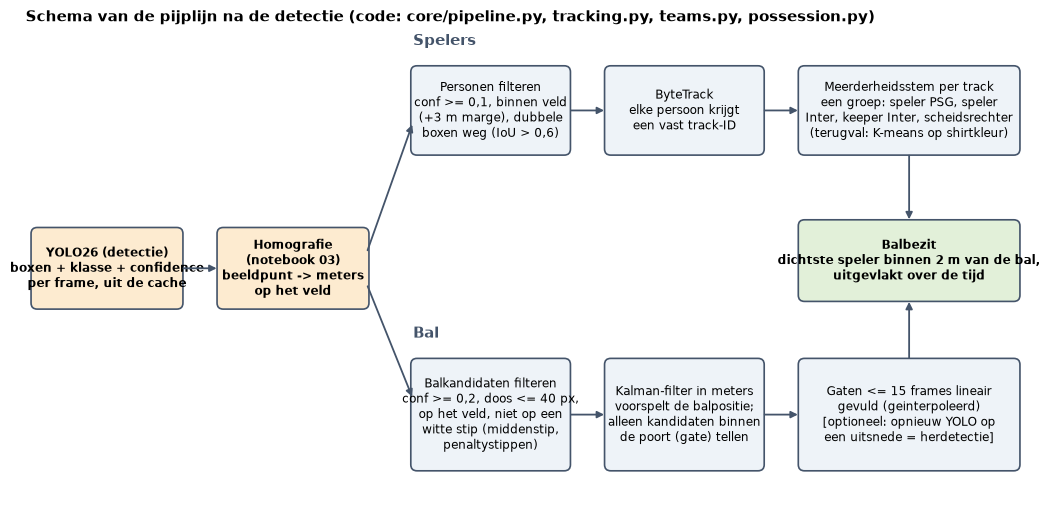

In [2]:
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13)
ax.set_ylim(0, 6.2)
ax.axis("off")


def box(x, y, w, h, text, fc="#EEF3F8", ec="#44546A", size=8.6, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size, fontweight="bold" if bold else "normal")


def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#44546A", lw=1.3))


box(0.1, 2.6, 1.9, 1.0, "YOLO26 (detectie)\nboxen + klasse + confidence\nper frame, uit de cache", fc="#FDEBD0", bold=True)
box(2.5, 2.6, 1.9, 1.0, "Homografie\n(notebook 03)\nbeeldpunt -> meters\nop het veld", fc="#FDEBD0", bold=True)
arrow(2.0, 3.1, 2.5, 3.1)
# people branch
box(5.0, 4.6, 2.0, 1.1, "Personen filteren\nconf >= 0,1, binnen veld\n(+3 m marge), dubbele\nboxen weg (IoU > 0,6)")
box(7.5, 4.6, 2.0, 1.1, "ByteTrack\nelke persoon krijgt\neen vast track-ID")
box(10.0, 4.6, 2.8, 1.1, "Meerderheidsstem per track\neen groep: speler PSG, speler\nInter, keeper Inter, scheidsrechter\n(terugval: K-means op shirtkleur)")
arrow(4.4, 3.3, 5.0, 5.0); arrow(7.0, 5.15, 7.5, 5.15); arrow(9.5, 5.15, 10.0, 5.15)
# ball branch
box(5.0, 0.5, 2.0, 1.4, "Balkandidaten filteren\nconf >= 0,2, doos <= 40 px,\nop het veld, niet op een\nwitte stip (middenstip,\npenaltystippen)")
box(7.5, 0.5, 2.0, 1.4, "Kalman-filter in meters\nvoorspelt de balpositie;\nalleen kandidaten binnen\nde poort (gate) tellen")
box(10.0, 0.5, 2.8, 1.4, "Gaten <= 15 frames lineair\ngevuld (geinterpoleerd)\n[optioneel: opnieuw YOLO op\neen uitsnede = herdetectie]")
arrow(4.4, 2.9, 5.0, 1.4); arrow(7.0, 1.2, 7.5, 1.2); arrow(9.5, 1.2, 10.0, 1.2)
# possession
box(10.0, 2.7, 2.8, 1.0, "Balbezit\ndichtste speler binnen 2 m van de bal,\nuitgevlakt over de tijd", fc="#E2F0D9", bold=True)
arrow(11.4, 4.6, 11.4, 3.7); arrow(11.4, 1.9, 11.4, 2.7)
ax.text(5.0, 6.0, "Spelers", fontsize=11, fontweight="bold", color="#44546A")
ax.text(5.0, 2.2, "Bal", fontsize=11, fontweight="bold", color="#44546A")
ax.set_title("Schema van de pijplijn na de detectie (code: core/pipeline.py, tracking.py, teams.py, possession.py)", loc="left")
plt.show()

Voor de lezer die de bestanden wil zien: de uitkomst van deze stappen wordt weggeschreven als `tracks_<model>.csv` (één rij per persoon per frame) en `frames_<model>.csv` (één rij per frame met de bal en het balbezit). Het datacontract staat in de docstring van `core/pipeline.py`. Hieronder controleren we dat wat we nu live uit de cache berekenen overeenkomt met de opgeslagen csv-bestanden uit de analysemap.

In [3]:
tr_saved = pd.read_csv(RES / "tracks_best.csv")
fr_saved = pd.read_csv(RES / "frames_best.csv")
tr_live = pd.DataFrame([{"frame": i, "track_id": p["track_id"], "group": p["group"]} for i in base.ids for p in base.people[i]])
fr_live = pd.DataFrame({"frame": base.ids, "ball_state": ball_states(base),
                        "possession_team": [base.possession[i]["team"] for i in base.ids]})
cmp = pd.DataFrame({
    "opgeslagen csv": [len(tr_saved), tr_saved.track_id.nunique(), (fr_saved.ball_state == "detected").sum(),
                       (fr_saved.ball_state == "interpolated").sum(), (fr_saved.ball_state == "none").sum()],
    "live berekend": [len(tr_live), tr_live.track_id.nunique(), (fr_live.ball_state == "detected").sum(),
                      (fr_live.ball_state == "interpolated").sum(), (fr_live.ball_state == "none").sum()]},
    index=["rijen in tracks", "aantal tracks", "frames bal gedetecteerd", "frames bal geinterpoleerd", "frames zonder bal"])
display(cmp)
print("Per frame dezelfde balstatus en balbezit-team:",
      bool((fr_saved.ball_state.values == fr_live.ball_state.values).all()
           and (fr_saved.possession_team.values == fr_live.possession_team.values).all()))

,opgeslagen csv,live berekend
rijen in tracks,15606,15606
aantal tracks,41,41
frames bal gedetecteerd,308,308
frames bal geinterpoleerd,191,191
frames zonder bal,161,161


Per frame dezelfde balstatus en balbezit-team: True


## 2. Spelers volgen met ByteTrack

**Het idee.** ByteTrack (Zhang e.a., 2022) is een *tracking-by-detection*-methode: de detector werkt per frame, de tracker koppelt de boxen van opeenvolgende frames aan elkaar. Per track houdt hij een Kalman-filter bij met als toestand het middelpunt van de box, de beeldverhouding en de hoogte, plus de snelheid van elk van die vier. Per frame gebeurt dit:

1. **Voorspellen.** Het Kalman-filter van elke bestaande track schuift de box op naar waar die nu verwacht wordt.
2. **Eerste ronde: koppelen op IoU.** Tussen de voorspelde boxen en de *zekere* detecties (confidence >= `conf` = 0,3) wordt de overlap berekend (*intersection over union*, IoU). De kost is `1 - IoU` (met de confidence van de detectie erin verwerkt, `fuse_score`); het Hongaarse algoritme zoekt de koppeling met de laagste totale kost, en een koppeling met kost boven `MATCH_THRESH` = 0,8 wordt niet toegelaten.
3. **Tweede ronde: zwakke boxen.** De nog niet gekoppelde tracks worden daarna gekoppeld aan de *zwakke* detecties (confidence tussen `TRACK_LOW_THRESH` = 0,1 en 0,3), alleen op IoU. Dit is het kenmerkende idee van ByteTrack: een speler die half achter een andere speler staat krijgt een lagere confidence maar hoeft niet te verdwijnen. Daarbij mag de koppelkost hoogstens 0,5 zijn. Een zwakke box start nooit een nieuwe track.
4. **Nieuwe en verloren tracks.** Een zekere detectie zonder koppeling start een nieuwe track; die telt pas mee als hij in het volgende frame bevestigd wordt. Een track zonder koppeling blijft `TRACK_BUFFER` = 30 frames (1 s bij 30 beelden per seconde) als *verloren* bewaard en kan in die tijd hetzelfde ID terugkrijgen; daarna vervalt hij.

Onze instellingen (de constanten staan bovenaan `core/tracking.py`):

In [4]:
settings = pd.DataFrame([
    ("track_high_thresh = new_track_thresh", 0.3, "conf van `run(conf=...)`: alleen boxen met minstens deze zekerheid starten een nieuwe track en doen mee in de eerste ronde"),
    ("track_low_thresh (TRACK_LOW_THRESH)", tk.TRACK_LOW_THRESH, "boxen tussen 0,1 en 0,3 doen alleen mee in de tweede ronde (bestaande tracks vervolgen)"),
    ("track_buffer (TRACK_BUFFER)", tk.TRACK_BUFFER, "frames dat een verloren track blijft bestaan (30 frames = 1 s bij 30 fps)"),
    ("match_thresh (MATCH_THRESH)", tk.MATCH_THRESH, "maximale koppelkost (1 - IoU, met confidence erin verwerkt) in de eerste ronde"),
    ("fuse_score", True, "de confidence van de box weegt mee in de koppelkost"),
    ("DUPLICATE_IOU", tk.DUPLICATE_IOU, "twee persoonsboxen met IoU > 0,6 gelden als dezelfde persoon: de zekerste blijft"),
    ("PITCH_MARGIN", pipe.PITCH_MARGIN, "meter buiten de lijnen die nog meetelt; publiek en bankspelers vallen hierbuiten"),
], columns=["instelling", "waarde", "betekenis"])
display(settings)

,instelling,waarde,betekenis
0,track_high_thresh = new_track_thresh,0.3,conf van `run(conf=...)`: alleen boxen met min...
1,track_low_thresh (TRACK_LOW_THRESH),0.1,"boxen tussen 0,1 en 0,3 doen alleen mee in de ..."
2,track_buffer (TRACK_BUFFER),30,frames dat een verloren track blijft bestaan (...
3,match_thresh (MATCH_THRESH),0.8,"maximale koppelkost (1 - IoU, met confidence e..."
4,fuse_score,True,de confidence van de box weegt mee in de koppe...
5,DUPLICATE_IOU,0.6,"twee persoonsboxen met IoU > 0,6 gelden als de..."
6,PITCH_MARGIN,3.0,meter buiten de lijnen die nog meetelt; publie...


In [5]:
# Re-run the first steps of pipeline.run() on the cached detections, to see the intermediate numbers.
hs = pipe.Homographies()
raw = {f["frame"]: f["detections"] for f in det.detect(pipe.VIDEO, pipe.DEFAULT_WEIGHTS, 1280, 0.7, 0, 659, 1)}


def prepare_people(raw, conf=0.3, buffer=None, match=None):
    """Same steps as pipeline.run() for the people: filter, remove duplicates, ByteTrack, vote. Returns people + counts."""
    dets = copy.deepcopy(raw)
    people, counts = {}, []
    for idx in base.ids:
        n_raw = n_pitch = 0
        kept = []
        for d in dets.get(idx, []):
            if not teams.is_person(d) or d["conf"] < tk.TRACK_LOW_THRESH:
                continue
            n_raw += 1
            x1, y1, x2, y2 = d["box"]
            d["xy"] = hs.image_to_pitch([((x1 + x2) / 2, y2)], idx)[0]
            if pipe.on_pitch(d["xy"]):
                kept.append(d)
        n_pitch = len(kept)
        people[idx] = tk.remove_duplicates(kept)
        counts.append({"frame": idx, "persoonsboxen (conf >= 0,1)": n_raw, "op het veld": n_pitch,
                       "na dubbelen weg": len(people[idx])})
    with tuned(**{k: v for k, v in (("TRACK_BUFFER", buffer), ("MATCH_THRESH", match)) if v is not None}):
        tk.track_people(people, conf=conf, stride=1)
    votes = tk.vote_groups(people, teams.group_of)
    for row in counts:
        row["met track-ID"] = sum(d.get("track") is not None for d in people[row["frame"]])
    return people, votes, pd.DataFrame(counts).set_index("frame")


people, votes, counts = prepare_people(raw)
print("Gemiddeld aantal personen per frame in elke stap:")
display(counts.mean().round(1).to_frame("gemiddeld per frame").T)

Gemiddeld aantal personen per frame in elke stap:


,"persoonsboxen (conf >= 0,1)",op het veld,na dubbelen weg,met track-ID
gemiddeld per frame,25.3,25.2,24.1,23.6


Voor de tracker rekenen we eerst de voeten van elke persoon om naar meters, houden alleen personen binnen het veld plus 3 m marge (publiek en bankspelers vallen daarbuiten) en laten van twee sterk overlappende boxen (IoU > 0,6) alleen de zekerste staan: een model dat twee klassen kent zet soms twee boxen met verschillende klasse op één speler, en dat zou twee stippen op de minimap geven. Hieronder volgt hoeveel personen elke stap overhoudt.

**Aantal tracks tegenover het echte aantal spelers.** Op het veld staan 22 spelers (11 per team, de keeper inbegrepen) en een scheidsrechtersgroep (op frame 300 hieronder zijn drie mensen met die groep gemarkeerd: de scheidsrechter en op de zijlijnen twee assistent-scheidsrechters, voor zover we dat uit het beeld kunnen opmaken). ByteTrack heeft 41 track-ID's uitgedeeld. De Gantt-grafiek toont per track wanneer hij actief is: een speler hoort één lange balk te zijn, een korte balk is een stuk dat afgebroken is of een persoon die maar kort in beeld was.

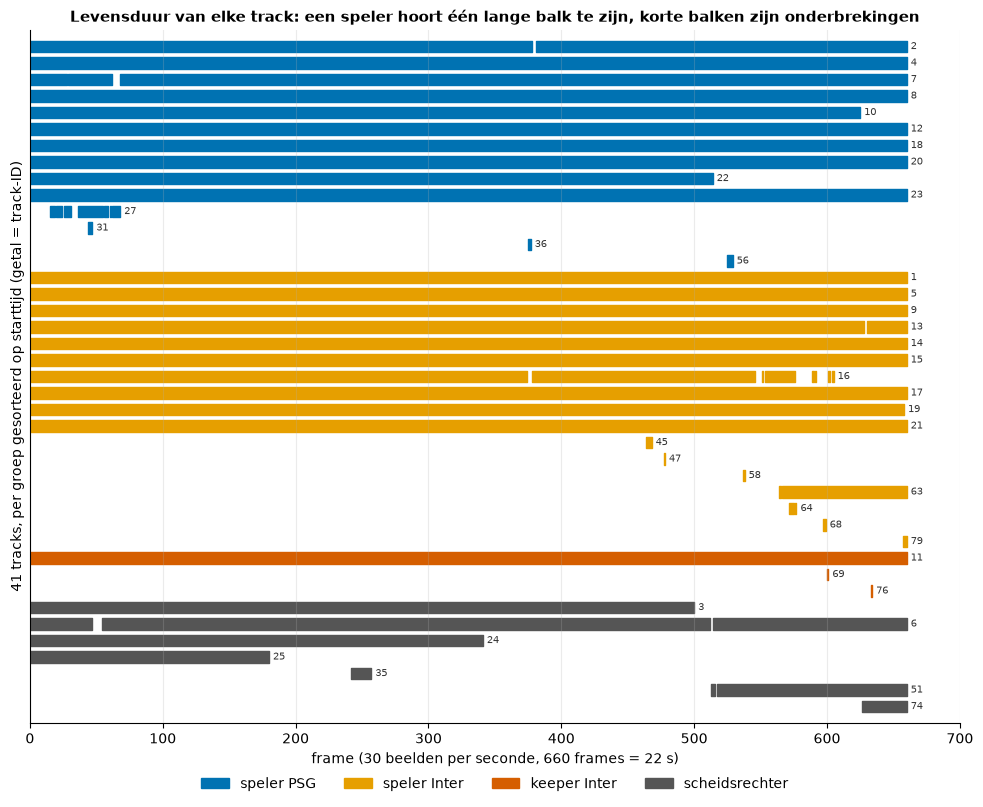

Tracks die de hele clip duren (start in de eerste en einde in de laatste 3 frames): 19
Tracks korter dan 2 s: 14 van 41; mediane duur 20.2 s
Tracks per groep: {'speler Inter': 17, 'speler PSG': 14, 'scheidsrechter': 7, 'keeper Inter': 3}
Tracks met een of meer gaten (frames waarin de track onzichtbaar was en daarna terugkwam): 9


In [6]:
life = (tr_live.groupby("track_id").agg(eerste=("frame", "min"), laatste=("frame", "max"), frames=("frame", "size"),
                                         groep=("group", lambda s: s.mode()[0])).reset_index())
life["duur_s"] = (life.laatste - life.eerste + 1) / base.fps
life["gaten"] = (life.laatste - life.eerste + 1) - life.frames
order = {"player_A": 0, "player_B": 1, "player_B_goal_keeper": 2, "referee": 3}
life = life.sort_values(["groep", "eerste"], key=lambda s: s.map(order) if s.name == "groep" else s).reset_index(drop=True)

frames_of = tr_live.groupby("track_id").frame.agg(set).to_dict()
fig, ax = plt.subplots(figsize=(12, 9))
for y, row in life.iterrows():
    present = frames_of[row.track_id]
    segs = [(a, b - a + 1) for k, a, b in runs_of([f in present for f in range(row.eerste, row.laatste + 1)]) if k]
    ax.broken_barh([(row.eerste + a, n) for a, n in segs], (y - 0.35, 0.7), color=C[row.groep])
    ax.text(row.laatste + 4, y, f"{row.track_id}", va="center", fontsize=7, color="#333")
ax.set_yticks([])
ax.set_ylim(len(life), -1)
ax.set_xlim(0, 700)
ax.set_xlabel("frame (30 beelden per seconde, 660 frames = 22 s)")
ax.set_ylabel(f"{len(life)} tracks, per groep gesorteerd op starttijd (getal = track-ID)")
handles = [Rectangle((0, 0), 1, 1, color=C[g]) for g in order]
ax.legend(handles, [NAME[g] for g in order], loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=4)
ax.set_title("Levensduur van elke track: een speler hoort één lange balk te zijn, korte balken zijn onderbrekingen")
plt.show()

full = life[(life.eerste <= 2) & (life.laatste >= 657)]
print(f"Tracks die de hele clip duren (start in de eerste en einde in de laatste 3 frames): {len(full)}")
print(f"Tracks korter dan 2 s: {(life.duur_s < 2).sum()} van {len(life)}; mediane duur {life.duur_s.median():.1f} s")
print("Tracks per groep:", life.groep.map(NAME).value_counts().to_dict())
print("Tracks met een of meer gaten (frames waarin de track onzichtbaar was en daarna terugkwam):", int((life.gaten > 0).sum()))

**Wat zien we.** Negentien tracks lopen vrijwel de hele clip (start in de eerste en einde in de laatste 3 frames) en de mediane duur van een track is 20,2 s van de 22 s. Veertien van de 41 tracks duren minder dan 2 s. Dat zijn de afgebroken stukken: een speler die kort uit beeld gaat, bijna volledig door een ander wordt afgedekt of waarvan het model enkele frames lang een lage confidence geeft, krijgt daarna soms een nieuw ID. Negen tracks hebben een gat (de speler was onzichtbaar en kreeg bij terugkomst hetzelfde ID terug): daar doet het buffer-mechanisme zijn werk. In de gemiddelde frame zijn 9,8 PSG-spelers, 10,0 Inter-spelers, 1,0 keeper en 2,8 scheidsrechtersgroep-personen getrackt; het aantal PSG-spelers zakt tegen het einde van de clip van 10 naar 9 en 8, waarschijnlijk omdat spelers dan uit beeld of buiten de marge staan (dat kunnen we uit deze cijfers niet afleiden).

In het rechterpaneel zien we dat de tracker bijna alles overhoudt wat de filters laten staan: van gemiddeld 24,1 personen per frame na het verwijderen van dubbele boxen krijgen er 23,6 een track-ID (98,2 %). De rest zijn nieuwe boxen die nog niet bevestigd zijn. In de eerste ±100 frames verwijdert de dubbelenfilter veel boxen (van maximaal 37 naar maximaal 29 per frame); dat zijn waarschijnlijk dubbele boxen met twee klassen op één speler, maar dat hebben we niet per geval nagekeken.

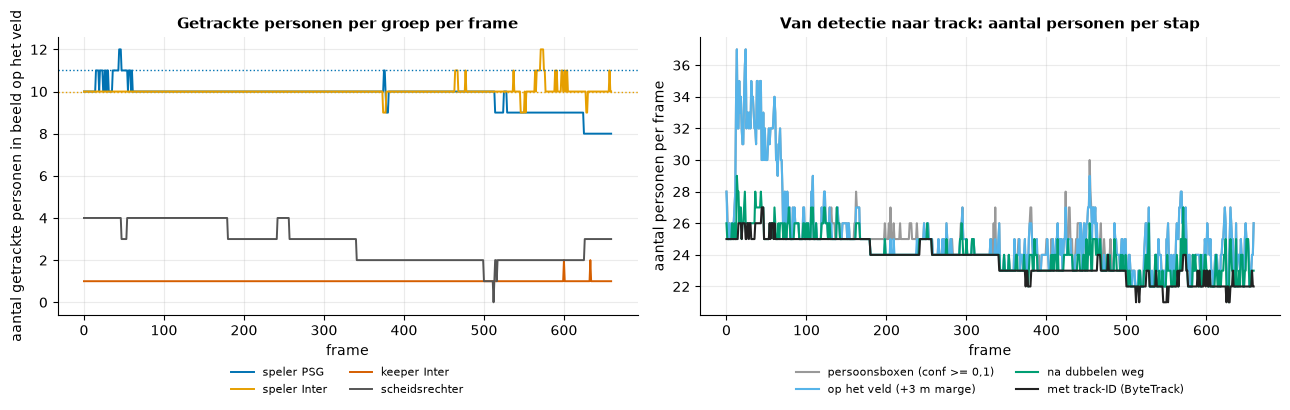

Gemiddeld per frame: {'speler PSG': 9.79, 'speler Inter': 10.03, 'keeper Inter': 1.0, 'scheidsrechter': 2.83}
Verhouding met track-ID tot na dubbelen weg: 0.982


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
persons = tr_live.groupby(["frame", "group"]).size().unstack(fill_value=0)
for g in order:
    ax.plot(persons.index, persons[g], color=C[g], label=NAME[g], lw=1.4)
ax.axhline(11, color=C["player_A"], ls=":", lw=1)
ax.axhline(10, color=C["player_B"], ls=":", lw=1)
ax.set_xlabel("frame")
ax.set_ylabel("aantal getrackte personen in beeld op het veld")
ax.set_title("Getrackte personen per groep per frame")
ax.legend(ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax = axes[1]
ax.plot(counts.index, counts["persoonsboxen (conf >= 0,1)"], color="#999999", label="persoonsboxen (conf >= 0,1)")
ax.plot(counts.index, counts["op het veld"], color="#56B4E9", label="op het veld (+3 m marge)")
ax.plot(counts.index, counts["na dubbelen weg"], color="#009E73", label="na dubbelen weg")
ax.plot(counts.index, counts["met track-ID"], color="#222222", label="met track-ID (ByteTrack)")
ax.set_xlabel("frame")
ax.set_ylabel("aantal personen per frame")
ax.set_title("Van detectie naar track: aantal personen per stap")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.show()
print("Gemiddeld per frame:", persons.mean().round(2).rename(NAME).to_dict())
print("Verhouding met track-ID tot na dubbelen weg:", round(counts["met track-ID"].sum() / counts["na dubbelen weg"].sum(), 3))

**Waarom een voorspelling nodig is.** Het koppelen op overlap werkt alleen als de box van een speler tussen twee frames genoeg overlapt met zichzelf. De grafiek meet dat op onze eigen tracks: de IoU van de box van dezelfde track na 1 frame is mediaan 0,91, na 10 frames (een derde seconde) 0,49 en na 30 frames 0,08. Een verloren track kan dus alleen teruggevonden worden als het Kalman-filter de box meebeweegt (positie plus snelheid); een speler die 1 s verdwenen was, is zonder voorspelling niet meer te koppelen op IoU. Dat verklaart de buffer van 30 frames: langer wachten levert een voorspelling op die te ver van de werkelijkheid ligt.

**ID-switches en waarom we ze niet konden meten.** Een ID-switch is het moment waarop een track van de ene speler overspringt naar een andere speler (twee spelers kruisen en wisselen van nummer), of waarop één speler na een onderbreking een nieuw nummer krijgt zodat zijn route in stukken uiteenvalt. Meten kan alleen met handgelabelde identiteiten over de tijd. Onze ground truth heeft die niet: de 22 lichaams-frames liggen 30 frames (1 s) uit elkaar en de 6 voeten-frames 4 s; de labeltool neemt een ID over binnen 5 m in het vorige gelabelde frame, en dat gaat op die afstanden te vaak mis (de labels bevatten 66 verschillende ID's voor 21 tot 25 personen per frame, bij de voeten-frames 75). De IDF1-lite-uitkomst van `evaluate_system.py` is daarom niet bruikbaar. Notebook 06 gaat daar verder op in.

Wat we wel kunnen laten zien is een *vermoeden*: een track eindigt en een nieuwe track van dezelfde groep begint binnen 1,5 s en 4 m van die plek. Dat is geen meting (het zegt niets over spelers die tussen twee tracks wisselen terwijl beide tracks blijven bestaan), maar het geeft een ondergrens voor het aantal stukken die waarschijnlijk dezelfde speler zijn.

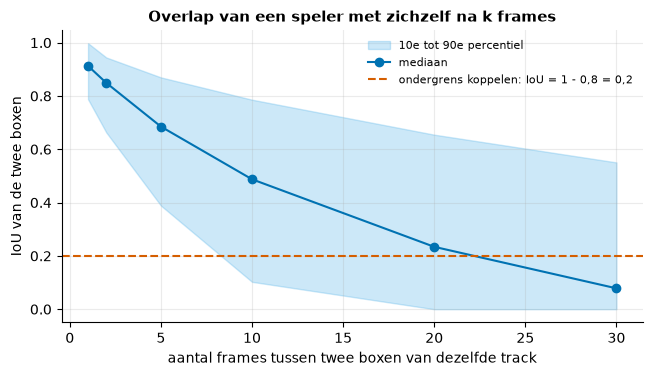

                    mediaan   p10   p90    paren
1 frames (0.03 s)      0.91  0.79  1.00  15543.0
2 frames (0.07 s)      0.85  0.66  0.94  15502.0
5 frames (0.17 s)      0.69  0.39  0.87  15390.0
10 frames (0.33 s)     0.49  0.10  0.79  15240.0
20 frames (0.67 s)     0.23  0.00  0.65  14951.0
30 frames (1.00 s)     0.08  0.00  0.55  14672.0


In [8]:
# Why a motion prediction is needed: how much does the box of the SAME track overlap itself after k frames?
def iou(a, b):
    return tk.iou(a, b)


boxes = {}
for i in base.ids:
    for p in base.people[i]:
        boxes.setdefault(p["track_id"], {})[i] = p["box"]
lags = [1, 2, 5, 10, 20, 30]
med = []
for lag in lags:
    vals = [iou(b[f], b[f + lag]) for b in boxes.values() for f in b if f + lag in b]
    med.append((np.median(vals), np.percentile(vals, 10), np.percentile(vals, 90), len(vals)))
med = np.array(med)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.fill_between(lags, med[:, 1], med[:, 2], color="#56B4E9", alpha=0.3, label="10e tot 90e percentiel")
ax.plot(lags, med[:, 0], "o-", color="#0072B2", label="mediaan")
ax.axhline(1 - tk.MATCH_THRESH, color="#D55E00", ls="--", label="ondergrens koppelen: IoU = 1 - 0,8 = 0,2")
ax.set_xlabel("aantal frames tussen twee boxen van dezelfde track")
ax.set_ylabel("IoU van de twee boxen")
ax.set_title("Overlap van een speler met zichzelf na k frames")
ax.legend(fontsize=8)
plt.show()
print(pd.DataFrame(med, index=[f"{l} frames ({l / 30:.2f} s)" for l in lags], columns=["mediaan", "p10", "p90", "paren"]).round(2))

In [9]:
# Probable ID switches (a heuristic, NOT a measurement): a track ends and a new track of the same group starts
# within 1.5 s and 4 m of where the first one ended. Tracks that end at the clip border are skipped.
ends = life[life.laatste < 655]
starts = life[life.eerste > 4]
pairs = []
for _, e in ends.iterrows():
    pe = base.people[int(e.laatste)]
    pe = next(p for p in pe if p["track_id"] == e.track_id)
    for _, s in starts[(starts.groep == e.groep) & (starts.eerste > e.laatste) & (starts.eerste - e.laatste <= 45)].iterrows():
        ps = next(p for p in base.people[int(s.eerste)] if p["track_id"] == s.track_id)
        d = float(np.hypot(pe["x_m"] - ps["x_m"], pe["y_m"] - ps["y_m"]))
        if d <= 4:
            pairs.append({"einde track": int(e.track_id), "frame einde": int(e.laatste), "begin track": int(s.track_id),
                          "frame begin": int(s.eerste), "groep": NAME[e.groep], "gat (frames)": int(s.eerste - e.laatste),
                          "afstand (m)": round(d, 1)})
pairs = pd.DataFrame(pairs)
print(f"Mogelijke ID-wissels (een track eindigt, dezelfde groep begint binnen 1,5 s en 4 m): {len(pairs)}")
display(pairs.head(12))

Mogelijke ID-wissels (een track eindigt, dezelfde groep begint binnen 1,5 s en 4 m): 5


,einde track,frame einde,begin track,frame begin,groep,gat (frames),afstand (m)
0,45,467,47,477,speler Inter,10,2.0
1,58,537,63,564,speler Inter,27,3.0
2,58,537,64,571,speler Inter,34,1.8
3,64,576,68,597,speler Inter,21,1.5
4,69,600,76,633,keeper Inter,33,1.9


We vinden 5 van zulke paren, alle bij Inter (waaronder de keeper) en in de tweede helft van de clip (frame 467 tot 633), en track 58 verschijnt twee keer als kandidaat-voorganger. Het echte aantal onderbrekingen is waarschijnlijk groter: 34 tracks voor de 22 spelers (inclusief de keeper) betekent dat er 12 track-ID's meer zijn dan er spelers zijn. De gevolgen zijn praktisch: afstanden en snelheden per track (notebook 05) zijn een ondergrens omdat een speler over meerdere tracks verdeeld kan zijn.

**Gevoeligheid.** We hebben `TRACK_BUFFER` en `MATCH_THRESH` gevarieerd en alleen de tracking opnieuw laten lopen. De drempel voor het koppelen is veel belangrijker dan de buffer: bij 0,8 (onze keuze) krijgen we 41 tracks voor elke buffer van 10 tot 90 frames, bij 0,6 loopt het aantal op tot 143 (veel koppelingen worden dan geweigerd, dus bijna elke speler wordt steeds opnieuw een nieuwe track), en bij 0,9 zakt het naar 37 tot 39. Minder tracks is niet vanzelf beter: zonder ID-meting weten we niet of een hogere drempel ook ten onrechte twee personen aan elkaar plakt. We laten daarom 0,8 staan, de standaard van ByteTrack.

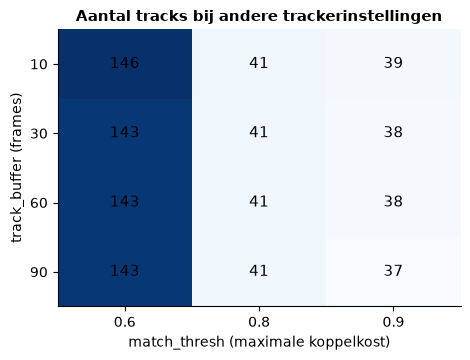

In [10]:
# Sensitivity of the number of tracks to the two tracker settings (re-tracking from cached detections, fast).
rows = []
for buf in (10, 30, 60, 90):
    for match in (0.6, 0.8, 0.9):
        p, _, _ = prepare_people(raw, buffer=buf, match=match)
        ids = {d["track"] for ds in p.values() for d in ds if d.get("track") is not None}
        rows.append({"track_buffer": buf, "match_thresh": match, "aantal tracks": len(ids)})
sens_tr = pd.DataFrame(rows).pivot(index="track_buffer", columns="match_thresh", values="aantal tracks")
fig, ax = plt.subplots(figsize=(5.2, 3.6))
im = ax.imshow(sens_tr.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(3), sens_tr.columns)
ax.set_yticks(range(4), sens_tr.index)
for i in range(4):
    for j in range(3):
        ax.text(j, i, int(sens_tr.values[i, j]), ha="center", va="center", color="black", fontsize=11)
ax.set_xlabel("match_thresh (maximale koppelkost)")
ax.set_ylabel("track_buffer (frames)")
ax.set_title("Aantal tracks bij andere trackerinstellingen")
ax.grid(False)
plt.show()

## 3. Teams en rollen

**Het model voorspelt de groep zelf.** Het finale model (`psg_vs_inter_CV.pt`) is getraind met vier persoonsklassen: `player_A` (PSG, donkerblauw), `player_B` (Inter, geel), `player_B_goal_keeper` (de keeper van Inter) en `referee`; daarnaast de klasse bal. De team-letter volgt uit de klasse (`TEAM_OF` in `core/teams.py`): A = PSG, B = Inter, en de keeper van Inter hoort bij team B. De scheidsrechter hoort bij geen team (`-`) en kan dus nooit balbezit hebben.

**De rol wordt per track vastgelegd, niet per frame.** Een model dat per frame een klasse geeft, flikkert soms: een speler is PSG in het ene frame en Inter in het volgende. `vote_groups` laat daarom elke track *één* groep krijgen: de klasse met de hoogste som van confidences over alle frames van die track (een gewogen meerderheidsstem). Eén fout frame draait het team van een speler dus niet om. Het kost niets: de stem is een som over de detecties die er al zijn.

Getrackte persoonsdetecties: 15606; daarvan met een andere klasse dan de gekozen groep van hun track: 150 (0.96 %)
Tracks met 100 % van de stemmen voor één groep: 38 van 41


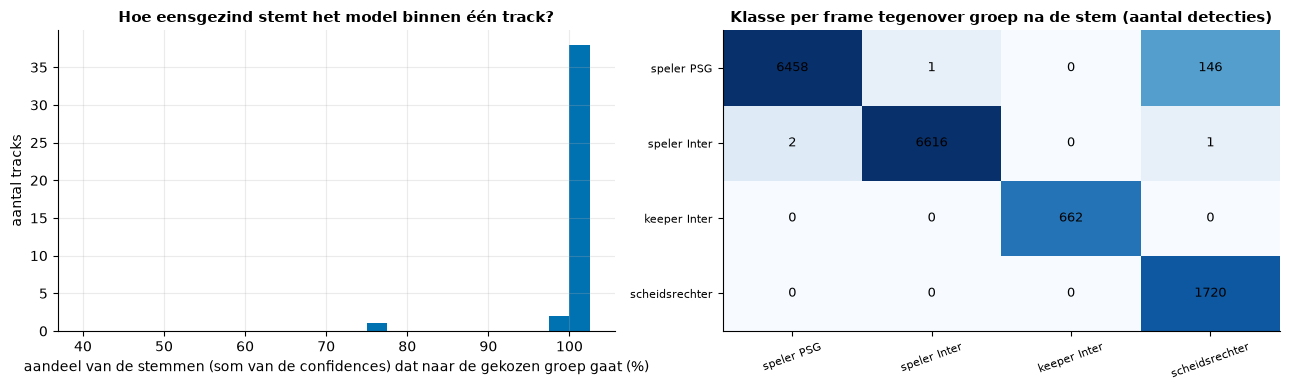

In [11]:
share = pd.DataFrame([{"track_id": t, "groep": NAME[g], "aandeel stemmen (%)": round(100 * s, 1)} for t, (g, s) in votes.items()])
n_det = sum(d.get("track") is not None for ds in people.values() for d in ds)
n_flip = sum(d.get("track") is not None and d["name"] != d["group"] for ds in people.values() for d in ds)
print(f"Getrackte persoonsdetecties: {n_det}; daarvan met een andere klasse dan de gekozen groep van hun track: {n_flip} ({100 * n_flip / n_det:.2f} %)")
print("Tracks met 100 % van de stemmen voor één groep:", int((share["aandeel stemmen (%)"] >= 99.95).sum()), "van", len(share))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.hist(share["aandeel stemmen (%)"], bins=np.arange(40, 105, 2.5), color="#0072B2")
ax.set_xlabel("aandeel van de stemmen (som van de confidences) dat naar de gekozen groep gaat (%)")
ax.set_ylabel("aantal tracks")
ax.set_title("Hoe eensgezind stemt het model binnen één track?")
ax = axes[1]
flips = pd.crosstab(pd.Series([d["name"] for ds in people.values() for d in ds if d.get("track") is not None], name="klasse van het model per frame"),
                    pd.Series([d["group"] for ds in people.values() for d in ds if d.get("track") is not None], name="groep na de stem"))
flips = flips.rename(index=NAME, columns=NAME)
im = ax.imshow(np.log10(flips.values + 1), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(flips.columns)), flips.columns, rotation=20, fontsize=8)
ax.set_yticks(range(len(flips.index)), flips.index, fontsize=8)
for i in range(flips.shape[0]):
    for j in range(flips.shape[1]):
        ax.text(j, i, flips.values[i, j], ha="center", va="center", fontsize=9)
ax.set_title("Klasse per frame tegenover groep na de stem (aantal detecties)")
ax.grid(False)
plt.tight_layout()
plt.show()

**Wat zien we.** Van de 15.606 getrackte persoonsdetecties wijkt de klasse van het model in 150 gevallen (0,96 %) af van de groep die de stem aan de track gaf; 38 van de 41 tracks hebben 100 % van de stemmen voor één groep. De rechter grafiek toont waar de afwijkingen zitten: bijna alle 150 zijn frames waarin het model `player_A` riep voor een track die als scheidsrechter eindigde (146 detecties). Of de stem hier de fout herstelt of dat de track twee personen samenvoegt, kunnen we zonder per frame naar de beelden te kijken niet beslissen. De lage eensgezindheid van één track (rond 76 % in het histogram) hoort bij dit geval.

De getallen per groep tonen hoe het resultaat in `tracks_best.csv` is opgebouwd: Inter 17 tracks en 6.617 persoon-frames, PSG 14 tracks en 6.460, keeper 3 tracks en 662 (de keeper is met één lange track vastgelegd, ID 11; de twee andere tracks, 69 en 76, zijn stukjes van enkele frames die naast hem bestaan), scheidsrechtersgroep 7 tracks en 1.867.

In [12]:
role = (tr_live.groupby("track_id").group.first().rename("groep").reset_index())
roles = pd.DataFrame({"tracks": role.groep.map(NAME).value_counts(),
                      "persoon-frames (rijen in tracks.csv)": tr_live.group.map(NAME).value_counts()})
roles["gemiddeld per frame"] = (roles["persoon-frames (rijen in tracks.csv)"] / len(base.ids)).round(2)
display(roles)

,tracks,persoon-frames (rijen in tracks.csv),gemiddeld per frame
speler Inter,17,6617,10.03
speler PSG,14,6460,9.79
scheidsrechter,7,1867,2.83
keeper Inter,3,662,1.00


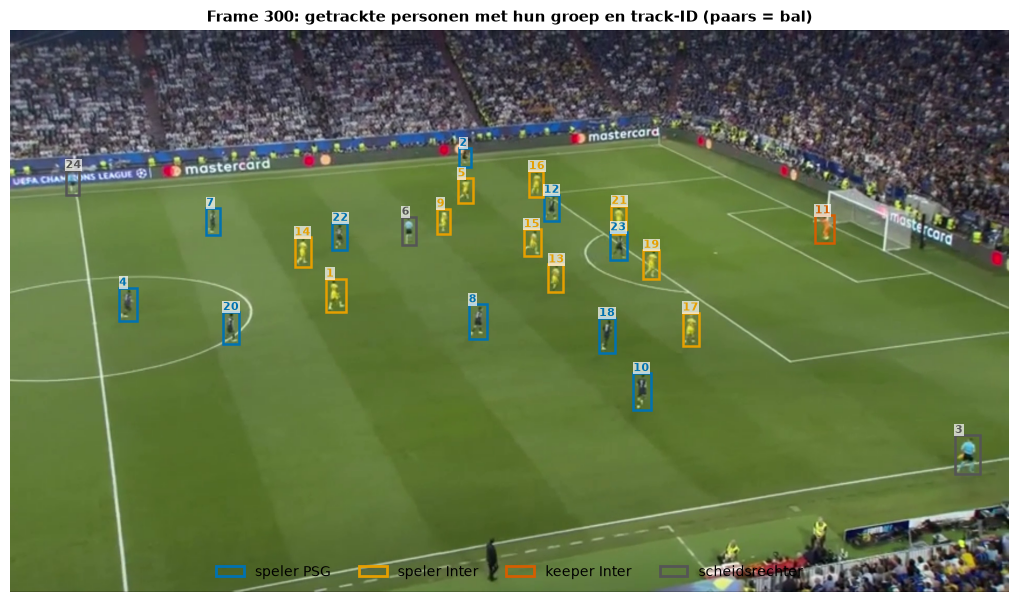

In [13]:
# Example frame: boxes coloured by group, with the track id.
FR = 300
img = cv2.cvtColor(read_frame(pipe.VIDEO, FR), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(figsize=(13, 7.3))
ax.imshow(img)
ax.axis("off")
for p in base.people[FR]:
    x1, y1, x2, y2 = p["box"]
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=C[p["group"]], lw=1.8))
    ax.text(x1, y1 - 4, str(p["track_id"]), color=C[p["group"]], fontsize=8, fontweight="bold",
            bbox=dict(fc="white", ec="none", alpha=0.7, pad=0.5))
b = base.ball.get(FR)
if b and b["box"]:
    x1, y1, x2, y2 = b["box"]
    ax.add_patch(Rectangle((x1 - 8, y1 - 8), x2 - x1 + 16, y2 - y1 + 16, fill=False, ec="#CC00CC", lw=1.5))
handles = [Rectangle((0, 0), 1, 1, fc="none", ec=C[g], lw=2) for g in order]
ax.legend(handles, [NAME[g] for g in order], loc="lower center", ncol=4, facecolor="white", framealpha=0.85)
ax.set_title(f"Frame {FR}: getrackte personen met hun groep en track-ID (paars = bal)")
plt.show()

**De K-means-terugval op shirtkleur.** Niet elk model kent teams. Een standaard COCO-model kent alleen de klasse `person`. Voor zo'n model gebruikt `assign_kmeans` de shirtkleur: per persoon nemen we het gemiddelde van de borstkas (bovenste helft van de box, middelste helft van de breedte) in de Lab-kleurruimte, laten gras (op basis van tint en verzadiging in HSV) buiten beschouwing, en verdelen alle personen met K-means (twee clusters, vaste seed) in `team 1` en `team 2`. Een shirt dat verder dan 2,5 keer de typische afstand van beide teamcentra ligt, krijgt `other` (scheidsrechter, keeper). De code roept dit alleen aan als er detecties met de klasse `person` of `player` zijn; met het finale model gebeurt dat dus nooit.

**Hoe goed werkt dat?** Eerlijk: *we hebben de terugval niet getest met een echt COCO-model.* Wat wel kan, is de kleurstap afzonderlijk testen op onze eigen detecties: we geven elke getrackte persoon de klasse `person` (de teamlabels van het model verbergen we) en laten K-means zijn werk doen. De uitkomst staat in de tabel en de spreidingsgrafiek (links: de groepen volgens het model, rechts de K-means-uitkomst). Het model zelf gebruiken we hier als referentie, dus dit meet hoe goed shirtkleur *op onze detecties* de teams scheidt, niet de detectie van een COCO-model (dat ook toeschouwers zou detecteren).

K-means op shirtkleur,other,team 1,team 2
groep volgens het model,,,
keeper Inter,345,316,1
scheidsrechter,1309,44,422
speler Inter,54,5613,8
speler PSG,148,62,5596


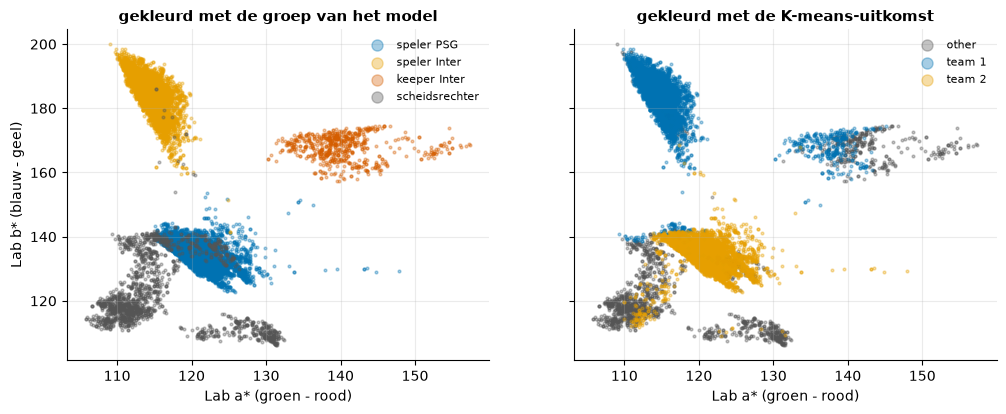

K-means team 1 is gelijk aan: speler Inter | team 2: speler PSG | other: scheidsrechter
Spelers PSG/Inter die K-means in het juiste team zet: 11209 van 11481 (97.6 %)


In [14]:
# K-means fallback, tested on OUR detections with the team labels hidden: every person is renamed to the generic
# class "person" (as a COCO model would give), then core.teams.assign_kmeans splits them on jersey colour.
generic = []
for idx in base.ids:
    for d in people[idx]:
        if d.get("jersey") and d.get("track") is not None:
            g = dict(d)
            g["name"] = "person"
            g.pop("kgroup", None)
            g["truth"] = d["group"]
            generic.append(g)
n_assigned = teams.assign_kmeans(generic)
km = pd.crosstab(pd.Series([NAME[g["truth"]] for g in generic], name="groep volgens het model"),
                 pd.Series([g["kgroup"] for g in generic], name="K-means op shirtkleur"))
display(km)
lab = np.array([g["jersey"] for g in generic])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True, sharey=True)
for ax, key, title in ((axes[0], "truth", "gekleurd met de groep van het model"), (axes[1], "kgroup", "gekleurd met de K-means-uitkomst")):
    for val in sorted({g[key] for g in generic}):
        pts = np.array([g["jersey"] for g in generic if g[key] == val])
        col = C.get(val, {"team 1": "#0072B2", "team 2": "#E69F00", "other": "#555555"}.get(val))
        ax.scatter(pts[:, 1], pts[:, 2], s=4, alpha=0.35, color=col, label=NAME.get(val, val))
    ax.set_xlabel("Lab a* (groen - rood)")
    ax.set_title(title)
    ax.legend(markerscale=4, fontsize=8)
axes[0].set_ylabel("Lab b* (blauw - geel)")
plt.show()
# map each K-means team to the model group that dominates it, to count the agreement
agree_team = {t: km[t].idxmax() for t in km.columns}
hit = sum(agree_team[g["kgroup"]] == NAME[g["truth"]] for g in generic)
players = [g for g in generic if g["truth"] in ("player_A", "player_B")]
hit_p = sum(1 for g in players if g["kgroup"] != "other" and agree_team[g["kgroup"]] == NAME[g["truth"]])
print("K-means team 1 is gelijk aan:", agree_team.get("team 1"), "| team 2:", agree_team.get("team 2"), "| other:", agree_team.get("other"))
print(f"Spelers PSG/Inter die K-means in het juiste team zet: {hit_p} van {len(players)} ({100 * hit_p / len(players):.1f} %)")

**Wat zien we.** K-means zet 97,6 % van de spelers (11.209 van 11.481, de detecties waarvan een shirtkleur te meten was) in het juiste team: PSG en Inter hebben duidelijk andere kleuren (donker tegenover geel). De scheidsrechter en de keeper worden minder goed gevonden: van de scheidsrechtersdetecties krijgt 74 % het label `other`, maar 422 van 1.775 (24 %) komen in `team 2`; van de keeper gaat 52 % naar `other` en 48 % naar `team 1`. Twee beperkingen volgen daaruit:

- De terugval kent de teams als `team 1` en `team 2` en codeert die in `TEAM_OF` als A en B. In onze test valt `team 1` samen met Inter en `team 2` met PSG; de koppeling met PSG = A is dus niet gegarandeerd.
- Scheidsrechters en keepers worden slechts gedeeltelijk als `other` herkend; ze kunnen het balbezit dan ten onrechte aan een team geven.

De terugval is een noodoplossing voor een model zonder teamklassen; het finale model heeft ze niet nodig.

## 4. De bal: het moeilijkste object

De bal is voor elke detector het moeilijkste object, en dat zien we in de cijfers van onze eigen cache (imgsz 1280, alle detecties met confidence >= 0,05):

- *Klein.* Een baldetectie is mediaan 14 pixels groot (10e tot 90e percentiel: 11 tot 18 px) in een beeld van 1920 x 1080; een speler is mediaan 54 px hoog. De bal beslaat dus maar enkele tientallen pixels en heeft weinig kenmerken.
- *Onzeker.* De confidence van baldetecties heeft een mediaan van 0,17 en slechts 13 % ligt boven 0,5; bij personen is de mediaan 0,72 en ligt 88 % boven 0,5. Het model is zelden zeker van de bal. In de bal-AP50 uit de PR-curves (notebook over detectie) zie je hetzelfde terug.
- *Onbetrouwbaar per frame.* In 174 van de 660 frames is er geen enkele baldetectie en in 272 frames zijn er twee of meer: witte stippen op het veld, laarzen en lijnstukken lijken op een bal. Er is dus niet één detectie per frame om te volgen.

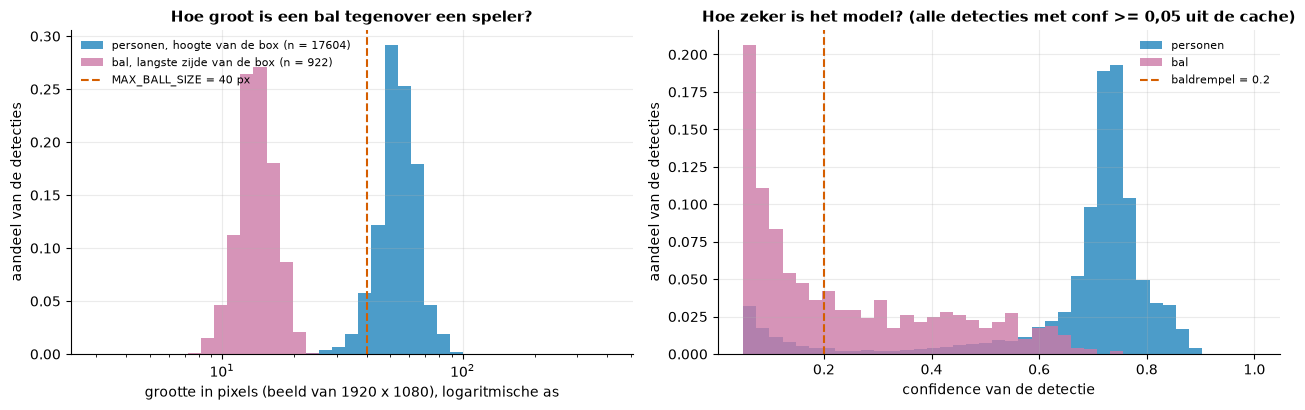

Bal: mediane grootte 14 px (10e-90e percentiel 11-18); mediane persoonshoogte 54 px
Confidence bal: mediaan 0.17, 13 % boven 0,5 | persoon: mediaan 0.72, 88 % boven 0,5
Aantal baldetecties (conf >= 0,05) per frame, aantal frames: {0: 174, 1: 214, 2: 155, 3: 81, 4: 27, 5: 7, 6: 2}


In [15]:
ball_dets = [d for ds in raw.values() for d in ds if teams.is_ball(d)]
person_dets = [d for ds in raw.values() for d in ds if teams.is_person(d)]
size_b = np.array([max(d["box"][2] - d["box"][0], d["box"][3] - d["box"][1]) for d in ball_dets])
size_p = np.array([d["box"][3] - d["box"][1] for d in person_dets])
conf_b = np.array([d["conf"] for d in ball_dets])
conf_p = np.array([d["conf"] for d in person_dets])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bins = np.geomspace(3, 400, 40)
ax.hist(size_p, bins=bins, color="#0072B2", alpha=0.7, label=f"personen, hoogte van de box (n = {len(size_p)})", weights=np.full(len(size_p), 1 / len(size_p)))
ax.hist(size_b, bins=bins, color="#CC79A7", alpha=0.8, label=f"bal, langste zijde van de box (n = {len(size_b)})", weights=np.full(len(size_b), 1 / len(size_b)))
ax.axvline(pipe.MAX_BALL_SIZE, color="#D55E00", ls="--", label=f"MAX_BALL_SIZE = {pipe.MAX_BALL_SIZE} px")
ax.set_xscale("log")
ax.set_xlabel("grootte in pixels (beeld van 1920 x 1080), logaritmische as")
ax.set_ylabel("aandeel van de detecties")
ax.set_title("Hoe groot is een bal tegenover een speler?")
ax.legend(fontsize=8)
ax = axes[1]
bins = np.linspace(0.05, 1, 40)
ax.hist(conf_p, bins=bins, color="#0072B2", alpha=0.7, label="personen", weights=np.full(len(conf_p), 1 / len(conf_p)))
ax.hist(conf_b, bins=bins, color="#CC79A7", alpha=0.8, label="bal", weights=np.full(len(conf_b), 1 / len(conf_b)))
ax.axvline(pipe.DEFAULT_BALL_CONF, color="#D55E00", ls="--", label=f"baldrempel = {pipe.DEFAULT_BALL_CONF}")
ax.set_xlabel("confidence van de detectie")
ax.set_ylabel("aandeel van de detecties")
ax.set_title("Hoe zeker is het model? (alle detecties met conf >= 0,05 uit de cache)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Bal: mediane grootte {np.median(size_b):.0f} px (10e-90e percentiel {np.percentile(size_b, 10):.0f}-{np.percentile(size_b, 90):.0f}); "
      f"mediane persoonshoogte {np.median(size_p):.0f} px")
print(f"Confidence bal: mediaan {np.median(conf_b):.2f}, {100 * (conf_b >= 0.5).mean():.0f} % boven 0,5 | "
      f"persoon: mediaan {np.median(conf_p):.2f}, {100 * (conf_p >= 0.5).mean():.0f} % boven 0,5")
per_frame = Counter(len([d for d in ds if teams.is_ball(d)]) for ds in raw.values())
print("Aantal baldetecties (conf >= 0,05) per frame, aantal frames:", dict(sorted(per_frame.items())))

**Kandidaten filteren.** Daarom nemen we alleen detecties mee die voldoen aan vier eisen (`ball_candidate` in `pipeline.py`): confidence >= de baldrempel (0,2), langste zijde van de box <= 40 px (een grotere 'bal' is een hoofd of een bord), een positie op het veld (+3 m marge) en minstens 1 m van de middenstip en de twee penaltystippen (witte stippen die op een bal lijken). Wat dan overblijft heet een *kandidaat*.

De trechter hieronder toont wat elk filter doet. De baldrempel doet het meeste werk: van de 922 baldetecties blijven 419 over, het grootte- en het veldfilter verwijderen er 0 en 1 en het stippenfilter 20. De 398 kandidaten liggen in 318 frames; het Kalman-filter accepteert er in 308 frames een als bal (zie hieronder).

,aantal
"alle baldetecties (conf >= 0,05)",922
conf >= 0.2,419
doos <= 40 px,419
op het veld (+3 m),418
niet op een witte stip,398
door het Kalman-filter geaccepteerd (frames),308


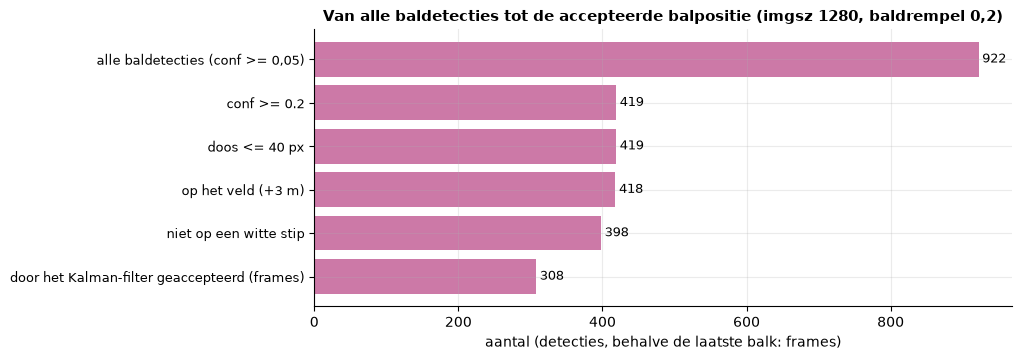

Frames met minstens een balkandidaat: 318 van 660; door het Kalman-filter als bal geaccepteerd: 308


In [16]:
def funnel(raw, ball_conf):
    """How many ball detections survive each filter of pipeline.ball_candidate()? (pitch position per detection)."""
    n = Counter()
    frames_with = set()
    for idx, ds in raw.items():
        for d in ds:
            if not teams.is_ball(d):
                continue
            n["alle baldetecties (conf >= 0,05)"] += 1
            x1, y1, x2, y2 = d["box"]
            if d["conf"] < ball_conf:
                continue
            n[f"conf >= {ball_conf}"] += 1
            if max(x2 - x1, y2 - y1) > pipe.MAX_BALL_SIZE:
                continue
            n[f"doos <= {pipe.MAX_BALL_SIZE} px"] += 1
            xy = hs.image_to_pitch([((x1 + x2) / 2, (y1 + y2) / 2)], idx)[0]
            if not pipe.on_pitch(xy):
                continue
            n["op het veld (+3 m)"] += 1
            if min(np.hypot(*np.subtract(xy, s)) for s in pipe.SPOTS) <= pipe.SPOT_RADIUS:
                continue
            n["niet op een witte stip"] += 1
            frames_with.add(idx)
    return n, frames_with


n_f, frames_with = funnel(raw, pipe.DEFAULT_BALL_CONF)
acc = sum(1 for i in base.ids if i in base.ball and base.ball[i]["state"] == "detected")
fun = pd.Series(n_f)
fun["door het Kalman-filter geaccepteerd (frames)"] = acc
display(fun.to_frame("aantal"))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(range(len(fun))[::-1], fun.values, color="#CC79A7")
ax.set_yticks(range(len(fun))[::-1], fun.index, fontsize=9)
for y, v in zip(range(len(fun))[::-1], fun.values):
    ax.text(v + 5, y, str(int(v)), va="center", fontsize=9)
ax.set_xlabel("aantal (detecties, behalve de laatste balk: frames)")
ax.set_title("Van alle baldetecties tot de accepteerde balpositie (imgsz 1280, baldrempel 0,2)")
plt.show()
print(f"Frames met minstens een balkandidaat: {len(frames_with)} van 660; door het Kalman-filter als bal geaccepteerd: {acc}")

**Het Kalman-filter in meters.** De baltrack gebruikt een Kalman-filter met constante snelheid, geschreven in numpy in `BallKalman`. De toestand is `(x, y, vx, vy)`: de positie in meters op het veld en de snelheid in meters per frame. We werken in meters en niet in pixels omdat de camera de bal bij het verre doel veel kleiner afbeeldt dan bij het nabije doel; een snelheid in pixels zou dan van plek tot plek anders zijn. Bij elk frame:

1. **Voorspellen:** `x' = F x` (de positie schuift een snelheidsstap op) en de onzekerheid `P' = F P F^T + Q` groeit met de procesruis `Q` (de bal kan van snelheid veranderen: trap, stuit).
2. **De poort (*gate*):** alleen balkandidaten binnen `BALL_GATE` + `BALL_GATE_GROWTH` x (aantal frames zonder meting) meter van de voorspelde positie tellen mee. De poort bepaalt dus of een witte laars ver weg wordt genegeerd. Is er een kandidaat in de poort, dan kiest de tracker de dichtstbijzijnde.
3. **Corrigeren:** `x = x + K (z - H x)`: de gemeten positie `z` trekt de schatting bij, in verhouding tot de meetruis `R` (detectie- en homografiefout, 0,3 m^2 per as) tegenover de onzekerheid `P`. Dit is de Kalman-versterking `K`.
4. **Geen kandidaat in de poort:** het frame krijgt geen meting; na `BALL_MAX_MISSED` = 30 zulke frames vervalt de track. Een nieuwe track start op een kandidaat met confidence >= `BALL_START_CONF` = 0,25. Een zekere kandidaat (>= 0,45) buiten de poort vervangt een zwakke koppeling (< 0,2).

**De gate-fix.** De eerste versie liet de poort slechts 1,0 m per frame groeien en schakelde na 15 gemiste frames af. Bij de trap rond frame 203 ging de bal in één stap van stilliggen naar 1,4 tot 2 m per frame (in onze data 2,2 m tussen frame 203 en 204): de voorspelling (de snelheid was nog 0) bleef bij de plek van de trap, de bal vloog weg en liet de poort achter zich (zie de grafiek hierboven: een bal van 1,4 m/frame is na ongeveer 5 gemiste frames buiten de oude poort). De track werd weggegooid en de frames 204 tot 218 bleven zonder bal terwijl de bal gewoon zichtbaar was en gedetecteerd werd. De oplossing (in `track_ball`): poortgroei van 1,0 naar 1,5 m/frame, `BALL_MAX_MISSED` van 15 naar 30, en een *herstart*: een zekere kandidaat (>= 0,4) buiten de poort start de track opnieuw als een kandidaat in de volgende 3 frames hem voortzet op hoogstens 1,5 m/frame. Eén losse uitschieter neemt de track dus niet over.

**Interpolatie over gaten.** Is een ballose stuk kort, dan trekken we een rechte lijn tussen de laatste en de eerstvolgende meting (`interpolate_ball`), in meters: alleen als beide metingen in hetzelfde *segment* liggen (er zat geen herstart tussen) en het gat hoogstens `MAX_BALL_GAP` = 15 frames (0,5 s) is. Zulke frames krijgen de status `interpolated`. Een langer gat blijft leeg: we verzinnen geen ballen.

Alle constanten van de baltracking:

In [17]:
ball_settings = pd.DataFrame([
    ("MAX_BALL_SIZE (pipeline)", pipe.MAX_BALL_SIZE, "px: een grotere 'bal' is iets anders (hoofd, bord)"),
    ("PITCH_MARGIN (pipeline)", pipe.PITCH_MARGIN, "m buiten de lijnen die nog meetelt"),
    ("SPOT_RADIUS (pipeline)", pipe.SPOT_RADIUS, "m: kandidaten dichter dan dit bij middenstip of een penaltystip worden genegeerd"),
    ("DEFAULT_BALL_CONF (pipeline)", pipe.DEFAULT_BALL_CONF, "minimale confidence van een kandidaat"),
    ("BALL_START_CONF", tk.BALL_START_CONF, "confidence om een nieuwe baltrack te starten"),
    ("BALL_WEAK", tk.BALL_WEAK, "een gekoppelde kandidaat onder deze confidence heet 'zwak'"),
    ("BALL_SWITCH_CONF", tk.BALL_SWITCH_CONF, "een zekere kandidaat (>= dit) buiten de poort vervangt een zwakke koppeling"),
    ("BALL_GATE", tk.BALL_GATE, "m: straal van de poort rond de voorspelling"),
    ("BALL_GATE_GROWTH", tk.BALL_GATE_GROWTH, "m extra poortstraal per frame zonder meting"),
    ("BALL_MAX_MISSED", tk.BALL_MAX_MISSED, "frames zonder meting voor de track vervalt"),
    ("BALL_RESTART_CONF", tk.BALL_RESTART_CONF, "zekerheid waarmee een kandidaat buiten de poort de track mag herstarten ..."),
    ("BALL_RESTART_LOOKAHEAD", tk.BALL_RESTART_LOOKAHEAD, "... als binnen zoveel frames een kandidaat hem voortzet ..."),
    ("BALL_RESTART_SPEED", tk.BALL_RESTART_SPEED, "... op hoogstens zoveel m/frame afstand"),
    ("MAX_BALL_GAP (pipeline)", pipe.MAX_BALL_GAP, "frames: grootste gat dat lineair geinterpoleerd wordt"),
], columns=["constante", "waarde", "betekenis"])
display(ball_settings)

,constante,waarde,betekenis
0,MAX_BALL_SIZE (pipeline),40.00,"px: een grotere 'bal' is iets anders (hoofd, b..."
1,PITCH_MARGIN (pipeline),3.00,m buiten de lijnen die nog meetelt
2,SPOT_RADIUS (pipeline),1.00,m: kandidaten dichter dan dit bij middenstip o...
3,DEFAULT_BALL_CONF (pipeline),0.20,minimale confidence van een kandidaat
4,BALL_START_CONF,0.25,confidence om een nieuwe baltrack te starten
5,BALL_WEAK,0.20,een gekoppelde kandidaat onder deze confidence...
6,BALL_SWITCH_CONF,0.45,een zekere kandidaat (>= dit) buiten de poort ...
7,BALL_GATE,2.00,m: straal van de poort rond de voorspelling
8,BALL_GATE_GROWTH,1.50,m extra poortstraal per frame zonder meting
9,BALL_MAX_MISSED,30.00,frames zonder meting voor de track vervalt


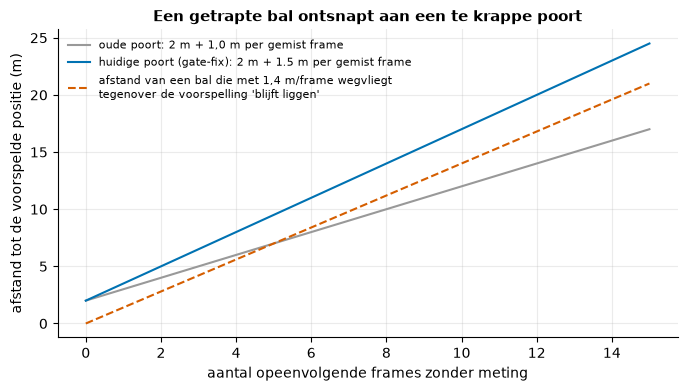

In [18]:
# Part 1: the gate as a function of the number of missed frames.
miss = np.arange(0, 16)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(miss, tk.BALL_GATE + 1.0 * miss, color="#999999", label="oude poort: 2 m + 1,0 m per gemist frame")
ax.plot(miss, tk.BALL_GATE + tk.BALL_GATE_GROWTH * miss, color="#0072B2", label=f"huidige poort (gate-fix): {tk.BALL_GATE:g} m + {tk.BALL_GATE_GROWTH:g} m per gemist frame")
ax.plot(miss, 1.4 * miss, color="#D55E00", ls="--", label="afstand van een bal die met 1,4 m/frame wegvliegt\ntegenover de voorspelling 'blijft liggen'")
ax.set_xlabel("aantal opeenvolgende frames zonder meting")
ax.set_ylabel("afstand tot de voorspelde positie (m)")
ax.set_title("Een getrapte bal ontsnapt aan een te krappe poort")
ax.legend(fontsize=8)
plt.show()

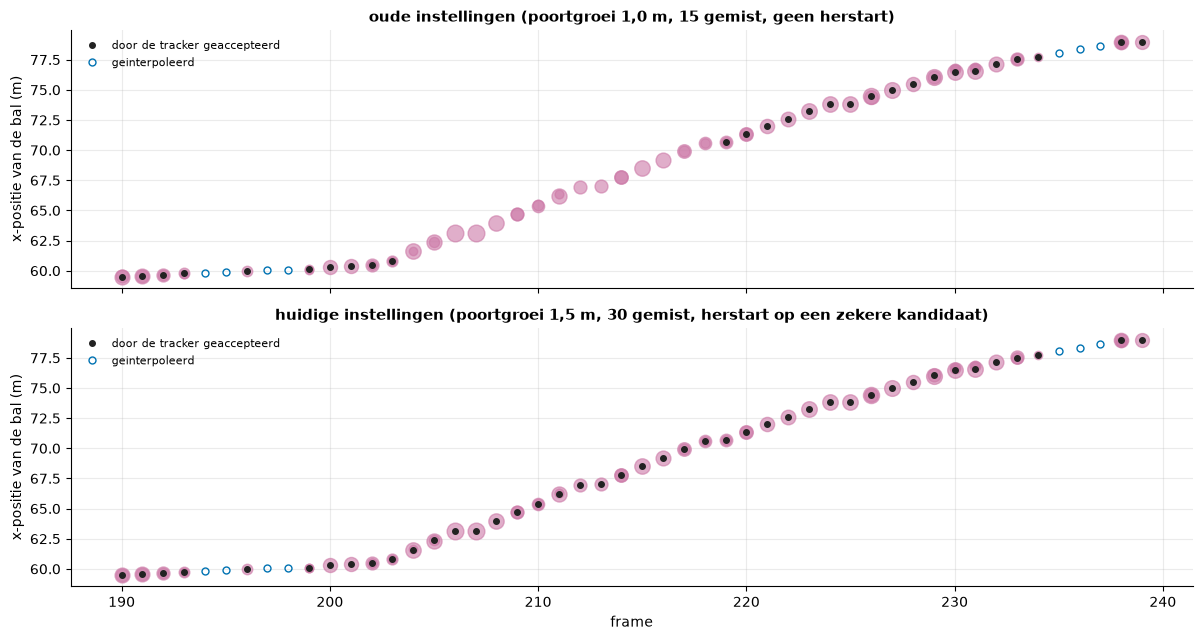

Frames 200-224 zonder bal met de oude instellingen: 15 (frames [204] t/m [218]); met de huidige: 0


In [19]:
# Part 2: the real case. Ball candidates (imgsz 960, threshold 0.1: the setting of the experiments) and the tracker
# with the old settings (gate growth 1.0, max 15 missed frames, no restart) against the current ones.
raw960 = {f["frame"]: f["detections"] for f in det.detect(pipe.VIDEO, pipe.DEFAULT_WEIGHTS, 960, 0.7, 0, 659, 1)}


def candidates_of(raw_, ball_conf):
    out = {}
    for idx in base.ids:
        for d in raw_.get(idx, []):
            c = pipe.ball_candidate(d, idx, hs, ball_conf)
            if c is not None:
                out.setdefault(idx, []).append(c)
    return out


def track_with(cands, **knobs):
    with tuned(**knobs):
        return tk.track_ball(cands, base.ids, pipe.MAX_BALL_GAP, pipe.BALL_START_CONF, pipe.BALL_WEAK)


c960 = candidates_of(raw960, 0.1)
t_old = track_with(c960, BALL_GATE_GROWTH=1.0, BALL_MAX_MISSED=15, BALL_RESTART_CONF=9.9)
t_new = track_with(c960)
W = range(190, 240)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, tr_, title in ((axes[0], t_old, "oude instellingen (poortgroei 1,0 m, 15 gemist, geen herstart)"),
                       (axes[1], t_new, "huidige instellingen (poortgroei 1,5 m, 30 gemist, herstart op een zekere kandidaat)")):
    for f in W:
        for xy, cf, _ in c960.get(f, []):
            ax.scatter(f, xy[0], s=20 + 160 * cf, color="#CC79A7", alpha=0.6, zorder=2)
    meas = [(f, tr_[f][0][0]) for f in W if f in tr_ and not tr_[f][2]]
    interp = [(f, tr_[f][0][0]) for f in W if f in tr_ and tr_[f][2]]
    ax.plot(*zip(*meas), "o", color="#222222", ms=4, label="door de tracker geaccepteerd", zorder=3)
    if interp:
        ax.plot(*zip(*interp), "o", mfc="none", color="#0072B2", ms=5, label="geinterpoleerd", zorder=3)
    ax.set_ylabel("x-positie van de bal (m)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlabel("frame")
plt.tight_layout()
plt.show()
gap_old = [f for f in range(200, 225) if f not in t_old]
gap_new = [f for f in range(200, 225) if f not in t_new]
print(f"Frames 200-224 zonder bal met de oude instellingen: {len(gap_old)} (frames {gap_old[:1]} t/m {gap_old[-1:]}); met de huidige: {len(gap_new)}")

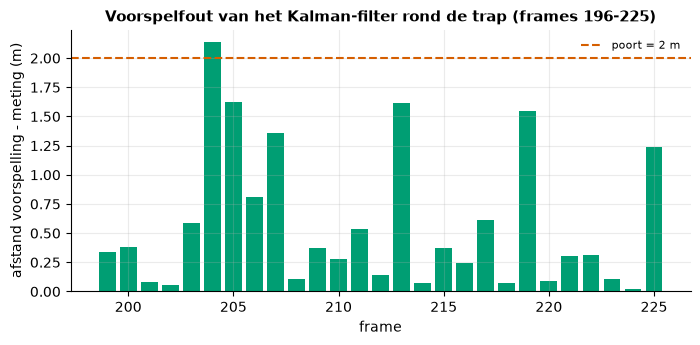

Mediane voorspelfout: 0.34 m; grootste: 2.14 m (frame 204)
Filterinstellingen:  Q = [0.05, 0.05, 0.1, 0.1]  R = [0.3, 0.3]  startonzekerheid P0 = [0.5, 0.5, 1.0, 1.0]


In [20]:
# Kalman filter in practice: predicted position before each measurement versus the measured position.
kf, pred_err = None, []
for f in range(196, 226):
    if f not in t_new or t_new[f][2]:
        if kf is not None:
            kf.predict()
        continue
    xy = t_new[f][0]
    if kf is None:
        kf = tk.BallKalman(xy)
    else:
        pred = kf.predict()
        pred_err.append((f, float(np.hypot(*(np.asarray(xy) - pred)))))
        kf.update(xy)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar([f for f, _ in pred_err], [e for _, e in pred_err], color="#009E73")
ax.axhline(tk.BALL_GATE, color="#D55E00", ls="--", label=f"poort = {tk.BALL_GATE:g} m")
ax.set_xlabel("frame")
ax.set_ylabel("afstand voorspelling - meting (m)")
ax.set_title("Voorspelfout van het Kalman-filter rond de trap (frames 196-225)")
ax.legend(fontsize=8)
plt.show()
print(f"Mediane voorspelfout: {np.median([e for _, e in pred_err]):.2f} m; grootste: {max(e for _, e in pred_err):.2f} m (frame {max(pred_err, key=lambda t: t[1])[0]})")
print("Filterinstellingen:  Q =", np.diag(tk.BallKalman.Q).tolist(), " R =", np.diag(tk.BallKalman.R).tolist(), " startonzekerheid P0 =", [0.5, 0.5, 1.0, 1.0])

**Wat zien we.** Het eerste figuur laat zien dat de oude poort een bal die plots 1,4 m per frame aflegt na ongeveer 5 gemiste frames kwijt is, de nieuwe niet. Het tweede figuur toont de echte situatie: met de oude instellingen mist de tracker de frames 204 tot 218 (15 frames) terwijl er in elk van die frames een kandidaat is (roze), met de huidige instellingen blijft de baan doorlopen. Het derde figuur geeft de voorspelfout van het Kalman-filter rond de trap: mediaan 0,34 m, met één piek van 2,14 m op frame 204, het frame direct na de trap (het filter dacht nog dat de bal stilligt). Daarnaast zijn er uitschieters tot 1,6 m (frames 205, 213 en 219); de poort van 2 m (plus groei per gemist frame) laat ruimte voor zulke afwijkingen, maar frame 204 zit er vlak onder.

De volgende grafieken tonen het resultaat voor de hele clip: eerst per frame welke toestand de bal heeft (`detected`, `interpolated` of `none`; de toestand `refined` hoort bij de optionele herdetectie en komt in de standaardrun niet voor), daarna het balspoor op het veld.

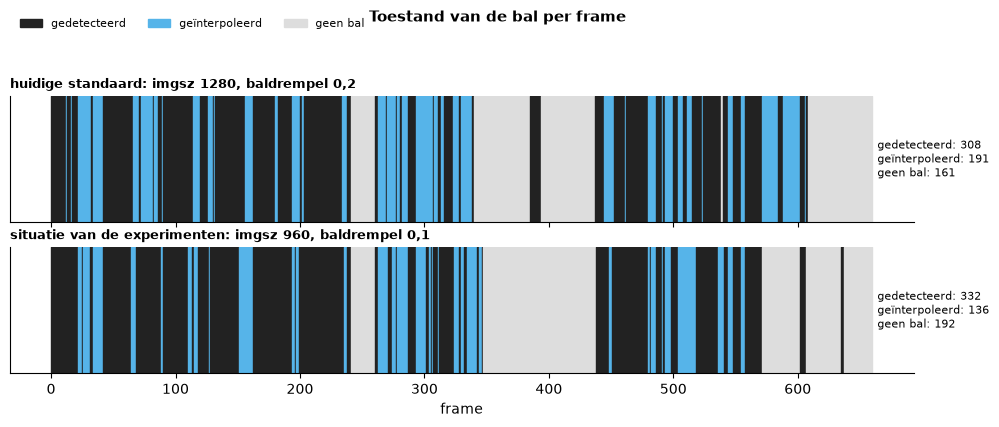

Aaneengesloten stukken zonder bal (huidige standaard):


,eerste frame,laatste frame,lengte (frames)
0,241,259,19
1,340,384,45
2,394,436,43
3,538,539,2
4,608,659,52


In [21]:
fig, axes = plt.subplots(2, 1, figsize=(13, 3.6), sharex=True)
for ax, res, title in ((axes[0], base, "huidige standaard: imgsz 1280, baldrempel 0,2"),
                       (axes[1], analyse(960, 0.1), "situatie van de experimenten: imgsz 960, baldrempel 0,1")):
    for st, a, b in runs_of(ball_states(res)):
        ax.broken_barh([(a, b - a + 1)], (0, 1), color=C[st])
    ax.set_yticks([])
    ax.set_ylim(0, 1)
    ax.set_title(title, loc="left", fontsize=9)
    ax.grid(False)
    c = Counter(ball_states(res))
    ax.text(664, 0.5, "\n".join(f"{STATE_NL[s]}: {c[s]}" for s in ("detected", "interpolated", "none")), va="center", fontsize=8)
axes[1].set_xlabel("frame")
axes[0].legend([Rectangle((0, 0), 1, 1, color=C[s]) for s in ("detected", "interpolated", "none")],
               [STATE_NL[s] for s in ("detected", "interpolated", "none")], ncol=3, loc="lower left", bbox_to_anchor=(0, 1.45), fontsize=8)
fig.suptitle("Toestand van de bal per frame", fontsize=11, fontweight="bold", y=1.12)
plt.subplots_adjust(right=0.82)
plt.show()

gaps = pd.DataFrame([(a, b, b - a + 1) for st, a, b in runs_of(ball_states(base)) if st == "none"], columns=["eerste frame", "laatste frame", "lengte (frames)"])
print("Aaneengesloten stukken zonder bal (huidige standaard):")
display(gaps)

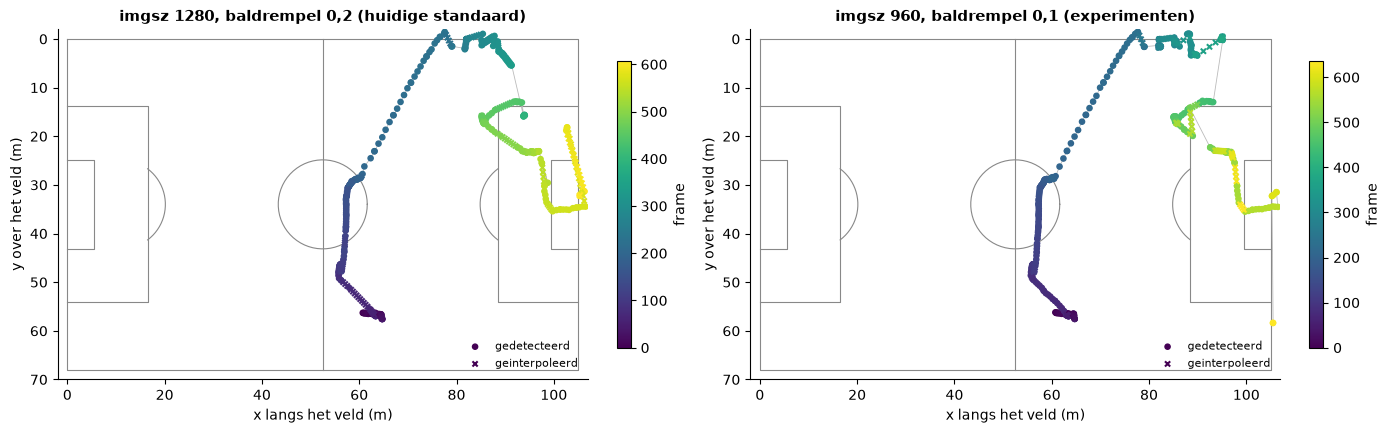

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, res, title in ((axes[0], base, "imgsz 1280, baldrempel 0,2 (huidige standaard)"), (axes[1], analyse(960, 0.1), "imgsz 960, baldrempel 0,1 (experimenten)")):
    draw_pitch(ax, 0.8)
    ids_ = [i for i in res.ids if i in res.ball]
    xy = np.array([[res.ball[i]["x_m"], res.ball[i]["y_m"]] for i in ids_])
    ax.plot(xy[:, 0], xy[:, 1], color="#BBBBBB", lw=0.6, zorder=2)
    det_ = [k for k, i in enumerate(ids_) if res.ball[i]["state"] == "detected"]
    int_ = [k for k, i in enumerate(ids_) if res.ball[i]["state"] != "detected"]
    sc = ax.scatter(xy[det_, 0], xy[det_, 1], c=np.array(ids_)[det_], cmap="viridis", s=14, zorder=3, label="gedetecteerd")
    ax.scatter(xy[int_, 0], xy[int_, 1], c=np.array(ids_)[int_], cmap="viridis", s=14, marker="x", zorder=3, label="geinterpoleerd")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
    plt.colorbar(sc, ax=ax, fraction=0.025, label="frame")
plt.tight_layout()
plt.show()

**Wat zien we.** In de standaardinstelling (imgsz 1280, baldrempel 0,2) hebben 499 van de 660 frames een bal: 308 gedetecteerd en 191 geinterpoleerd. De vijf stukken zonder bal zijn 19 frames (241-259), 45 (340-384), 43 (394-436), 2 (538-539) en 52 (608-659). Het laatste stuk begint bij frame 608, vlak voor het moment waarop volgens de conclusie van het experiment de keeper de bal vasthoudt (frames 607-630; de bal zat volgens die conclusie in de frames 571-601 in het doel en was niet zichtbaar). Het balspoor op het veld volgt de bal van het middenveld naar de bovenste zijlijn en daarna naar het rechter doel (x = 105); de kruisjes (geinterpoleerd) liggen op rechte stukken tussen metingen.

De onderste tijdlijn toont de situatie van de experimenten (imgsz 960, baldrempel 0,1): daar zijn er meer gedetecteerde frames (332) maar minder geinterpoleerde (136) en meer frames zonder bal (192). Later in dit notebook rekenen we beide settings na.

## 5. De bal-experimenten

Naast de standaardtracker is in `experiments/ball_prediction/` onderzocht of de bal in frames zonder detectie te voorspellen valt uit eerdere frames. Het script `run_experiments.py` (te zien in `data/results/bal_experimenten/`) draait alle varianten op de gecachete detecties van het model, in twee opstellingen:

- **E1, gesimuleerde gaten.** Waarheid = de 195 frames waarin de bal met confidence >= 0,3 gedetecteerd is. In een venster van k = 5, 10, 20 of 40 frames worden alle kandidaten met confidence >= 0,1 verborgen en kijken we of de methode de bal terugvindt binnen 25 px. 40 vensters per gatlengte (voor de crop-methoden minder: 5 tot 6).
- **E2, de echte gaten** in de hele clip van 660 frames, met als maat het aantal frames zonder bal en de controle op de handgelabelde frames (21 frames met zichtbare bal, 7 zonder).

| Methode | Wat het doet |
|---|---|
| M0 | de oorspronkelijke tracker (poortgroei 1,0 m, 15 gemiste frames, geen herstart) |
| M1 | langere interpolatie (<= 30 of <= 60 frames) en extrapolatie (de bal een vast aantal frames met constante of afnemende snelheid laten doorvliegen) |
| M2 | zwakke detecties (confidence >= 0,05) binnen een strakke of ruime poort |
| M3 | herdetectie: YOLO opnieuw op een uitsnede (*crop*) rond de verwachte plek, op de schaal van het hele frame (crop 640 px, `imgsz` 320) of opgeschaald (320 px x 3) |
| M4 | visuele trackers: template matching en OpenCV `TrackerMIL` |
| M5 | de gate-fix (poortgroei 1,5 m, 30 gemist, herstart), ook gecombineerd met M1 |
| M6 | alles samen: M5 + M2 + M3 + M1-vulling |

De volledige tabel van de echte gaten (E2) uit `results.json`:

In [23]:
e = json.load(open(RES / "results.json", encoding="utf-8"))
e2 = pd.DataFrame({m: {"gedetecteerd": v["states"].get("detected", 0), "geinterpoleerd": v["states"].get("interp", 0),
                       "geextrapoleerd": v["states"].get("extrap", 0), "zwak": v["states"].get("weak", 0),
                       "crop": v["states"].get("crop", 0), "tracker": v["states"].get("tracker", 0),
                       "geen bal": v["states"].get("none", 0), "GT gegeven (van 21)": v["gt"]["ok"] + v["gt"]["wrong"],
                       "GT binnen 25 px": v["gt"]["ok"], "valse bal (van 7)": v["gt"]["false"]} for m, v in e["e2"].items()}).T
display(e2)

,gedetecteerd,geinterpoleerd,geextrapoleerd,zwak,crop,tracker,geen bal,GT gegeven (van 21),GT binnen 25 px,valse bal (van 7)
M0 basis,302,119,0,0,0,0,239,15,14,4
M1a interp<=30,302,115,0,0,0,0,243,14,14,4
M1b interp<=60,302,182,0,0,0,0,176,16,16,5
M1c interp60+extrap15,302,182,64,0,0,0,112,18,17,5
M1d interp60+extrap30 decay,302,182,109,0,0,0,67,20,17,7
M5a gate-fix,332,132,0,0,0,0,196,15,15,5
M5b gate-fix + interp60 + extrap15,332,210,49,0,0,0,69,19,18,7
M2a zwak strak,302,116,0,43,0,0,199,14,14,5
M2b zwak ruim,302,125,0,68,0,0,165,15,15,5
M2c zwak size<=60 strak,302,116,0,43,0,0,199,14,14,5


**Wat zien we.**

- **De grootste winst komt van het repareren van de tracker (M5), niet van voorspellen.** De gate-fix brengt `detected` van 302 naar 332 en de frames zonder bal van 239 naar 196, zonder extra rekentijd. Het gat bij frame 204-218 was een weggegooide track (zie sectie 4).
- **Extrapolatie en lange interpolatie vullen veel frames, maar worden snel onbetrouwbaar.** Interpolatie tot 60 frames: bij een gat van 20 frames is 73 % van de ingevulde ballen goed (binnen 25 px) en bij 40 frames 60 %. Extrapolatie vooruit (M1e): 61 % goed bij 20 en 39 % bij 40 frames. Op de echte gaten (M1d) valt het aantal frames zonder bal van 239 naar 67, maar op de handgelabelde frames stijgt het aantal valse ballen van 4 naar 7 van de 7 (de bal staat dan in het net of bij de keeper, waar hij niet zichtbaar is).
- **Zwakke detecties (M2)** voegen 42 tot 77 frames toe, maar op de plaatjes zijn sommige twijfelachtig.
- **Herdetectie in een crop (M3)** vindt in de simulatie bijna alles (93 tot 100 % goed) maar de simulatie is optimistisch: het model ziet het echte frame, waarin de bal wel gevonden werd. Belangrijker is de bevinding dat het model **schaalgevoelig** is: een opgeschaalde crop (M3x, 320 px x 3) vond in de simulatie 0 van 12 ballen die het volledige frame wel vond. De bal moet op dezelfde schaal blijven als bij de training. Met een lage drempel (0,15) geeft M3d in de echte gaten ook valse treffers op de zijlijn (frames 334-337 en 629).
- **Visuele trackers (M4)** zien er in de simulatie goed uit (template matching: 81 % goed bij 20 en 40 frames), maar op de echte gaten geeft elke tracker een bal waar er geen is en de cirkel blijft op gras, een lijn of het doelnet hangen: er is geen goede stopregel voor een object van ±10 px. Template matching voegt 273 en TrackerMIL 291 frames toe, met 5 en 6 valse ballen op de zeven frames zonder zichtbare bal.
- **De bovengrens.** De schatting uit de plaatjes is dat van de 239 'none'-frames er maar 80 tot 85 echt een zichtbare bal hebben; de rest (bal in het doel, keeper met de bal in zijn handen) is niet te zien. Lange extrapolatie voegt daar alleen valse ballen toe.

Het volgende figuur zet de E2-resultaten naast elkaar: frames zonder bal (minder is vollediger), hoeveel van de 21 zichtbare handgelabelde ballen we een bal geven, en hoeveel van de 7 frames zonder zichtbare bal toch een bal krijgen (minder is beter).

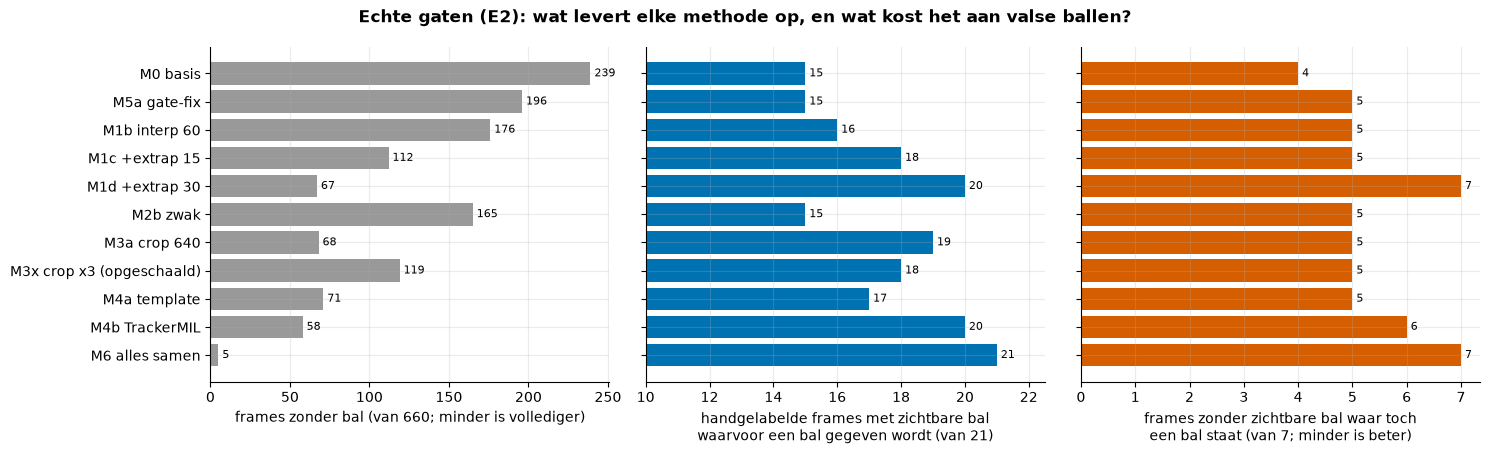

In [24]:
short = {"M0 basis": "M0 basis", "M5a gate-fix": "M5a gate-fix", "M1b interp<=60": "M1b interp 60",
         "M1c interp60+extrap15": "M1c +extrap 15", "M1d interp60+extrap30 decay": "M1d +extrap 30", "M2b zwak ruim": "M2b zwak",
         "M3a crop 640 x0.5 tau .15": "M3a crop 640", "M3x crop 320 x3 tau .15 (opgeschaald)": "M3x crop x3 (opgeschaald)",
         "M4a template matching": "M4a template", "M4b OpenCV TrackerMIL": "M4b TrackerMIL",
         "M6 M5 + M2a + M3a(640) + M1c vulling": "M6 alles samen"}
sel = e2.loc[list(short)].rename(index=short)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
y = np.arange(len(sel))[::-1]
axes[0].barh(y, sel["geen bal"], color="#999999")
axes[0].set_xlabel("frames zonder bal (van 660; minder is vollediger)")
axes[1].barh(y, sel["GT gegeven (van 21)"], color="#0072B2")
axes[1].set_xlim(10, 22.5)
axes[1].set_xlabel("handgelabelde frames met zichtbare bal\nwaarvoor een bal gegeven wordt (van 21)")
axes[2].barh(y, sel["valse bal (van 7)"], color="#D55E00")
axes[2].set_xlabel("frames zonder zichtbare bal waar toch\neen bal staat (van 7; minder is beter)")
for ax, col in zip(axes, ("geen bal", "GT gegeven (van 21)", "valse bal (van 7)")):
    ax.set_yticks(y, sel.index)
    for yy, v in zip(y, sel[col]):
        ax.text(v, yy, f" {int(v)}", va="center", fontsize=8)
fig.suptitle("Echte gaten (E2): wat levert elke methode op, en wat kost het aan valse ballen?", fontweight="bold")
plt.tight_layout()
plt.show()

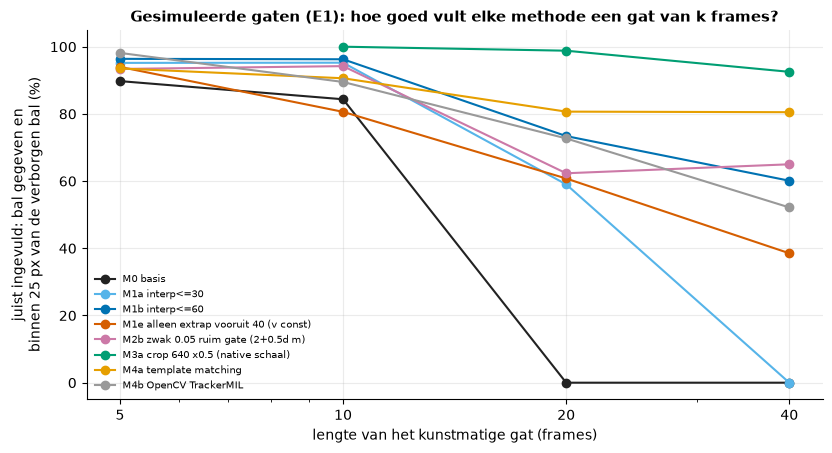

Aantal vensters / frames per gatlengte (M0): {'5': (40, 166), '10': (40, 294), '20': (40, 515), '40': (40, 880)}
M3a (crop) heeft maar {'5': None, '10': 6, '20': 6, '40': 5} vensters per gatlengte


In [25]:
ks = ["5", "10", "20", "40"]
pick = {"M0 basis": "#222222", "M1a interp<=30": "#56B4E9", "M1b interp<=60": "#0072B2", "M1e alleen extrap vooruit 40 (v const)": "#D55E00",
        "M2b zwak 0.05 ruim gate (2+0.5d m)": "#CC79A7", "M3a crop 640 x0.5 (native schaal)": "#009E73",
        "M4a template matching": "#E69F00", "M4b OpenCV TrackerMIL": "#999999"}
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for m, col in pick.items():
    ys = [e["e1"][m][k]["good"] if e["e1"][m].get(k) and e["e1"][m][k]["n"] > 0 else np.nan for k in ks]
    ax.plot([int(k) for k in ks], [100 * v for v in ys], "o-", color=col, label=m)
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 40], ["5", "10", "20", "40"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("lengte van het kunstmatige gat (frames)")
ax.set_ylabel("juist ingevuld: bal gegeven en\nbinnen 25 px van de verborgen bal (%)")
ax.set_title("Gesimuleerde gaten (E1): hoe goed vult elke methode een gat van k frames?")
ax.legend(fontsize=7, loc="lower left")
plt.show()
print("Aantal vensters / frames per gatlengte (M0):", {k: (e["e1"]["M0 basis"][k]["windows"], e["e1"]["M0 basis"][k]["n"]) for k in ks})
print("M3a (crop) heeft maar", {k: e["e1"]["M3a crop 640 x0.5 (native schaal)"].get(k, {}).get("windows") for k in ks}, "vensters per gatlengte")

Het tweede figuur toont de gesimuleerde gaten (E1): het percentage correct ingevulde ballen per gatlengte. Zonder hulp (M0) werkt de tracker tot ongeveer 10 frames (84 % goed bij 10) en daarna niet meer (0 % bij 20). Interpolatie tot 60 frames (M1b) is bij 20 frames nog 73 % goed; extrapolatie alleen (M1e) zakt sneller. De crop-methode M3a houdt het beste vol (99 % bij 20 en 93 % bij 40 frames), maar met slechts 5 tot 6 vensters en een model dat het echte frame ziet; de visuele trackers lopen uiteen (M4a 81 %, M4b 52 % bij 40 frames).

### Zelf narekenen uit de cache

Wat uit de cache kan, rekenen we hier opnieuw: de oude tracker (zonder herstart, poortgroei 1,0 m, 15 gemiste frames), de gate-fix en de gate-fix met herdetectie in de setting van de experimenten (imgsz 960, baldrempel 0,1), en de huidige standaard (imgsz 1280, baldrempel 0,2). Per variant tellen we de balstatussen, de handgelabelde frames (`GT met bal gegeven`: van de 21 frames met zichtbare bal geven we er zoveel een bal; `binnen 3 m`: daarvan met een fout kleiner dan 3 m; `valse bal`: van de 7 frames zonder zichtbare bal geven we er zoveel toch een bal) en het balbezit. Dit is een ruwe controle; de eigenlijke meting tegenover de ground truth staat in notebook 06.

In [26]:
# Recompute the variants that can run from the caches (no YOLO): the experiments' setting (imgsz 960, threshold 0.1).
def n_missing(res):
    return len(refine.missing_crops(res.video, res.weights, pipe.refine_windows(res)))


with tuned(BALL_GATE_GROWTH=1.0, BALL_MAX_MISSED=15, BALL_RESTART_CONF=9.9):
    r_old_ = pipe.run(imgsz=960, ball_conf=0.1)
with tuned(BALL_GATE_GROWTH=1.0, BALL_MAX_MISSED=15, BALL_RESTART_CONF=9.9):
    r_old_1280 = pipe.run(imgsz=1280, ball_conf=0.2)
r_fix = analyse(960, 0.1)
miss960 = n_missing(r_fix)
print(f"Ontbrekende crops in de cache voor imgsz 960 / drempel 0,1: {miss960}")
r_ref = analyse(960, 0.1, refine_ball=True) if miss960 == 0 else None
miss_def = n_missing(base)
print(f"Ontbrekende crops in de cache voor de huidige standaard (1280 / 0,2): {miss_def} van {len(pipe.refine_windows(base))}  -> ball_refine daar NIET gedraaid (zou YOLO starten)")
rows = {"M0 oude tracker (960, 0,1)": summary_row(r_old_), "M5a gate-fix (960, 0,1)": summary_row(r_fix)}
if r_ref is not None:
    rows["gate-fix + ball_refine (960, 0,1)"] = summary_row(r_ref)
rows["oude tracker (1280, 0,2)"] = summary_row(r_old_1280)
rows["huidige standaard (1280, 0,2)"] = summary_row(base)
recomputed = pd.DataFrame(rows).T
display(recomputed)

Ontbrekende crops in de cache voor imgsz 960 / drempel 0,1: 0


Ontbrekende crops in de cache voor de huidige standaard (1280 / 0,2): 156 van 161  -> ball_refine daar NIET gedraaid (zou YOLO starten)


,gedetecteerd,geïnterpoleerd,herdetectie,geen bal,GT met bal gegeven,binnen 3 m,valse bal,bezit PSG %,bezit Inter %,wissels
"M0 oude tracker (960, 0,1)",302,119,0,239,15/21,15/21,4/7,98.1,1.9,2
"M5a gate-fix (960, 0,1)",332,136,0,192,16/21,15/21,5/7,100.0,0,0
"gate-fix + ball_refine (960, 0,1)",332,136,1,191,17/21,16/21,5/7,100.0,0,0
"oude tracker (1280, 0,2)",305,181,0,174,19/21,19/21,5/7,91.9,8.1,3
"huidige standaard (1280, 0,2)",308,191,0,161,19/21,18/21,5/7,91.9,8.1,3


In [27]:
reported = pd.DataFrame({
    "M0 oude tracker (960, 0,1)": {"gedetecteerd": 302, "geïnterpoleerd": 119, "herdetectie": 0, "geen bal": 239, "GT met bal gegeven": "15/21", "valse bal": "4/7", "bezit PSG %": 93, "bezit Inter %": 7, "wissels": 4},
    "M5a gate-fix (960, 0,1)": {"gedetecteerd": 332, "geïnterpoleerd": 136, "herdetectie": 0, "geen bal": 192, "GT met bal gegeven": "16/21", "valse bal": "5/7", "bezit PSG %": 95, "bezit Inter %": 5, "wissels": 2},
    "gate-fix + ball_refine (960, 0,1)": {"gedetecteerd": 332, "geïnterpoleerd": 136, "herdetectie": 1, "geen bal": 191, "GT met bal gegeven": "17/21", "valse bal": "5/7", "bezit PSG %": 95, "bezit Inter %": 5, "wissels": np.nan},
    "huidige standaard (1280, 0,2)": {"gedetecteerd": np.nan, "geïnterpoleerd": np.nan, "herdetectie": np.nan, "geen bal": 161, "GT met bal gegeven": "19/21", "valse bal": "5/7", "bezit PSG %": np.nan, "bezit Inter %": np.nan, "wissels": np.nan}}).T
print("Gerapporteerd in WIJZIGINGEN.md en de projectgeschiedenis (leeg = niet gerapporteerd):")
display(reported)
cols = ["gedetecteerd", "geïnterpoleerd", "herdetectie", "geen bal"]
diff = recomputed[cols].astype(float).sub(reported[cols].astype(float).reindex(recomputed.index))
print("Verschil in aantal frames (nu berekend min gerapporteerd):")
display(diff)

Gerapporteerd in WIJZIGINGEN.md en de projectgeschiedenis (leeg = niet gerapporteerd):


,gedetecteerd,geïnterpoleerd,herdetectie,geen bal,GT met bal gegeven,valse bal,bezit PSG %,bezit Inter %,wissels
"M0 oude tracker (960, 0,1)",302,119,0,239,15/21,4/7,93,7,4
"M5a gate-fix (960, 0,1)",332,136,0,192,16/21,5/7,95,5,2
"gate-fix + ball_refine (960, 0,1)",332,136,1,191,17/21,5/7,95,5,NaN
"huidige standaard (1280, 0,2)",NaN,NaN,NaN,161,19/21,5/7,NaN,NaN,NaN


Verschil in aantal frames (nu berekend min gerapporteerd):


,gedetecteerd,geïnterpoleerd,herdetectie,geen bal
"M0 oude tracker (960, 0,1)",0.0,0.0,0.0,0.0
"M5a gate-fix (960, 0,1)",0.0,0.0,0.0,0.0
"gate-fix + ball_refine (960, 0,1)",0.0,0.0,0.0,0.0
"oude tracker (1280, 0,2)",NaN,NaN,NaN,NaN
"huidige standaard (1280, 0,2)",NaN,NaN,NaN,0.0


**Vergelijking met de gerapporteerde getallen.** De frametellingen komen **exact** overeen met wat in `WIJZIGINGEN.md` en de projectgeschiedenis staat: 302 / 119 / 239 voor de oude tracker, 332 / 136 / 192 voor de gate-fix en 332 / 136 / 1 / 191 voor de gate-fix met herdetectie, allemaal bij imgsz 960 en baldrempel 0,1. Ook het aantal handgelabelde ballen dat we vinden (15, 16 en 17 van 21) en de valse ballen (4, 5 en 5 van 7) komen overeen. Voor de huidige standaard (imgsz 1280, baldrempel 0,2) is 161 frames zonder bal en 19 van 21 gevonden, zoals in de geschiedenis staat.

Twee afwijkingen noemen we eerlijk:

1. **Balbezit.** Voor de oude tracker en de gate-fix rapporteert `WIJZIGINGEN.md` 93 % / 7 % met 4 wissels en 95 % / 5 % met 2 wissels; bij dezelfde ballen rekenen wij nu 98,1 % / 1,9 % (2 wissels) en 100 % / 0 % (0 wissels). De oorzaak is niet onderzocht. De frametellingen voor de bal zijn gelijk, dus de afwijking zit in de spelers: de persoonstracking van toen gaf 48 tracks (nu 47 bij imgsz 960) en 6.702 PSG-frames (nu 6.722), en een paar frames verschil in wie de dichtste speler is, verandert in een clip met maar enkele wissels meteen de percentages. Dit bevestigt hoe gevoelig het balbezit is (zie sectie 6).
2. **Het experiment tegenover de ingebouwde versie.** De M5a-variant in het experiment geeft 332 / 132 / 196, de ingebouwde code 332 / 136 / 192: vier frames minder interpolatie, oorzaak niet onderzocht (het experiment draait op een eigen kopie van de tracker).

**Waarom de nieuwe standaard anders is dan de experimenten.** De standaard is intussen imgsz 1280 en baldrempel 0,2 geworden (bepaald op de handgelabelde frames: 19 van 21 ballen gevonden tegenover 16 van 21 bij 960, met evenveel valse ballen). Het gevolg is 308 gedetecteerde frames in plaats van 332 (de hogere drempel gooit zwakke, juiste detecties weg), maar 191 in plaats van 136 geinterpoleerde frames (er zijn meer metingen, dus meer gaten die we overbruggen kunnen) en 161 in plaats van 192 frames zonder bal. De oorspronkelijke redenering staat in `core/pipeline.py`: 1280 ziet de kleine bal in meer frames dan de trainingsgrootte 960, en de baldrempel 0,2 verwijdert de statische valse ballen met confidence 0,11 tot 0,14 die 1280 erbij zet. De gate-fix levert op de nieuwe standaard minder op: de oude tracker met imgsz 1280 en drempel 0,2 geeft 305 / 181 / 174, de huidige 308 / 191 / 161 (13 frames zonder bal minder, hetzelfde aantal handgelabelde ballen).

**Herdetectie op de nieuwe standaard.** De crop-cache hoort bij de oude setting: voor imgsz 1280 en drempel 0,2 ontbreken 156 van de 161 benodigde crops. `ball_refine=True` zou dan YOLO starten; dat hebben we niet gedaan. Op de oude setting werkt de herdetectie wel uit de cache en geeft ze maar één extra `refined`-frame (332 / 136 / 1 / 191), 17 in plaats van 16 van de 21 handgelabelde ballen. Dat is veel minder dan de 36 crop-treffers in het experiment M3a: de ingebouwde versie eist een confidence van 0,3 én een bevestiging door een gedetecteerde bal of een tweede treffer binnen 3 frames, zodat de valse treffers van M3d eruit blijven.

De montages hieronder zijn de voorbeeldplaatjes uit het experiment (de uitsneden rond de verwachte plek, met de uitkomst van de methode erop).

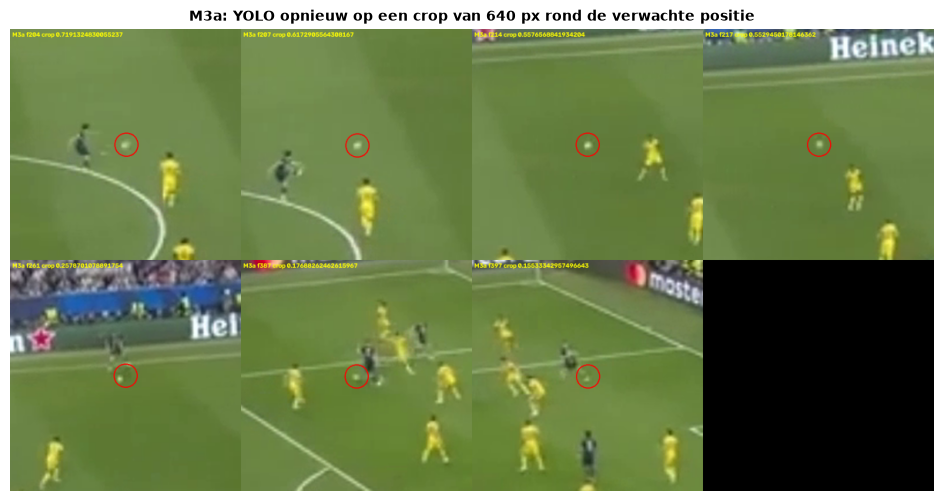

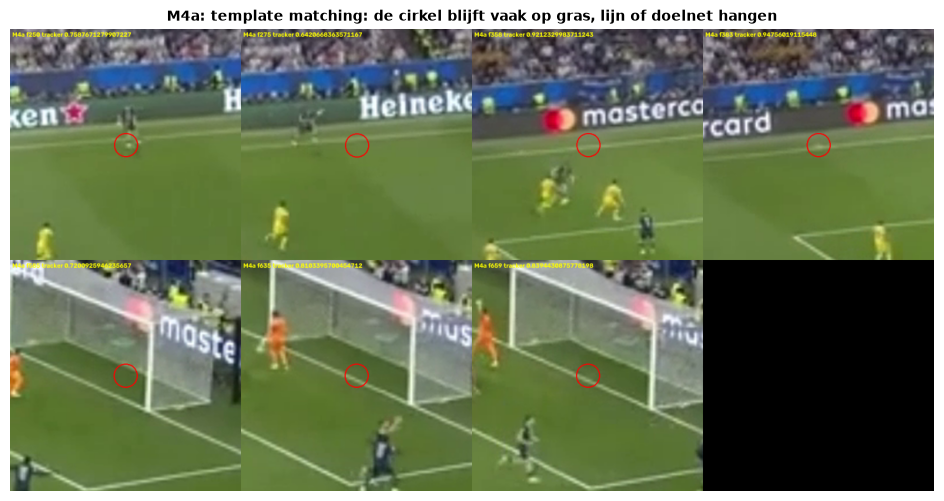

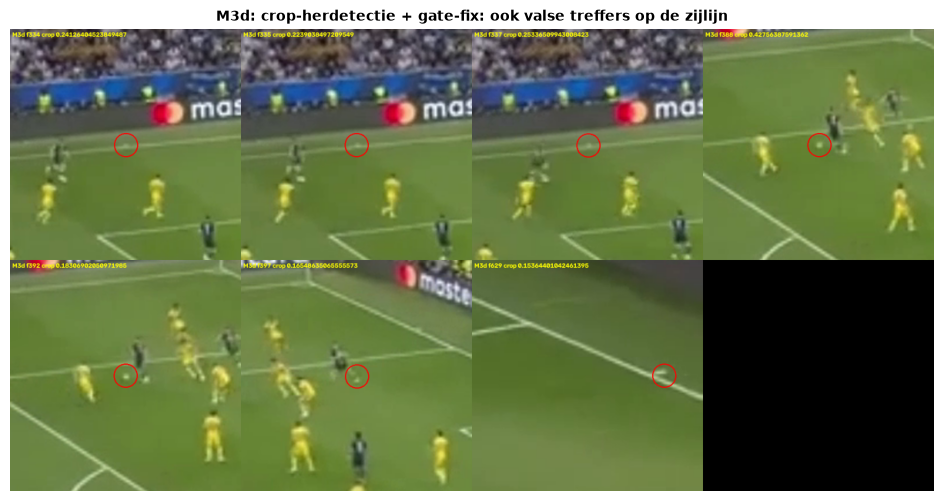

In [28]:
for name, caption in (("montage_M3a.png", "M3a: YOLO opnieuw op een crop van 640 px rond de verwachte positie"),
                      ("montage_M4a.png", "M4a: template matching: de cirkel blijft vaak op gras, lijn of doelnet hangen"),
                      ("montage_M3d.png", "M3d: crop-herdetectie + gate-fix: ook valse treffers op de zijlijn")):
    im = plt.imread(RES / name)
    fig, ax = plt.subplots(figsize=(12, 12 * im.shape[0] / im.shape[1]))
    ax.imshow(im)
    ax.axis("off")
    ax.set_title(caption, fontsize=10)
    plt.show()

**Wat is ingebouwd en wat niet.**

| Methode | Besluit | Reden |
|---|---|---|
| Gate-fix (M5) | **standaard aan** (in `core/tracking.py`) | herstelt een weggegooide track na een trap; gratis; +30 gedetecteerde frames in het experiment |
| Herdetectie in crops (M3, geschaald op `imgsz` 320 voor een crop van 640 px) | **ingebouwd, standaard uit** (`ball_refine=True` of `--ball-refine`) | in de ingebouwde, strengere vorm (confidence >= 0,3 plus bevestiging) maar +1 frame en +1 handgelabelde bal; kost ±0,3 s per crop op CPU en vooral een eerste keer rekentijd |
| Interpolatie <= 15 frames | **standaard aan** | bij gesimuleerde gaten van 5 en 10 frames is 95 % van de ingevulde ballen goed (E1, M1a) |
| Interpolatie 30 tot 60 frames (M1b) | niet ingebouwd | bij gaten van 20 tot 40 frames daalt het aandeel goede ballen tot 60-73 % |
| Extrapolatie (M1c-M1f) | niet ingebouwd | voegt valse ballen toe (4 naar 7 van 7 op de handgelabelde frames) in dode-bal-situaties |
| Zwakke detecties (M2) | niet ingebouwd | 42 tot 77 extra frames, maar sommige twijfelachtig en geen betrouwbare bevestiging |
| Visuele trackers (M4) | niet ingebouwd, afgeraden | cirkel blijft op gras, lijn of net hangen; 5-6 valse ballen |
| Opgeschaalde crops (M3x) | niet gebruiken | het model is schaalgevoelig: 0 van 12 treffers |
| NMS-vrij (`nms=False`) in YOLO | niet standaard | meer frames gevuld (175 in plaats van 192 zonder bal) en minder valse ballen (3/5 tegenover 4/5 in een eerdere meting), maar lagere balbezitnauwkeurigheid (0,68 tegenover 0,77; bron: `WIJZIGINGEN.md`) |

## 6. Balbezit

**De regel** (`core/possession.py`) heeft twee stappen:

1. **Per frame, ruw.** `raw_possession` pakt alle spelers van team A of B (scheidsrechters tellen niet mee) en meet voor elk de afstand tussen zijn voeten en de bal in meters. De dichtste speler 'heeft' de bal als die afstand hoogstens `POSSESSION_RADIUS` = 2,0 m is; zo niet (of als er geen bal is) heeft niemand de bal in dat frame.
2. **Uitvlakken in de tijd, met hysterese.** `stable_possession` verandert het balbezit pas als het andere team de bal `POSSESSION_SWITCH` = 5 opeenvolgende frames heeft (anders blijft het vorige team staan) en laat het bezit pas vervallen naar 'niemand' na `POSSESSION_TIMEOUT` = 15 frames zonder dat iemand binnen de straal is. Een enkel frame waarin een tegenstander langs de bal loopt, wisselt het bezit dus niet.

De uitkomst per frame is `possession_team` (A, B of `-`) en `possession_track_id`: het ID van de dichtste speler, alleen ingevuld zolang zijn team het (uitgevlakte) bezit heeft.

Waar de eenvoud de grenzen heeft: de homografie zet het beeldpunt van de bal om alsof hij op het gras ligt; een bal in de lucht komt dus op een verkeerde plek op het veld. Ook weten we niets over wie 'echt' controle heeft (een tegenstander die de bal even raakt zonder hem te winnen).

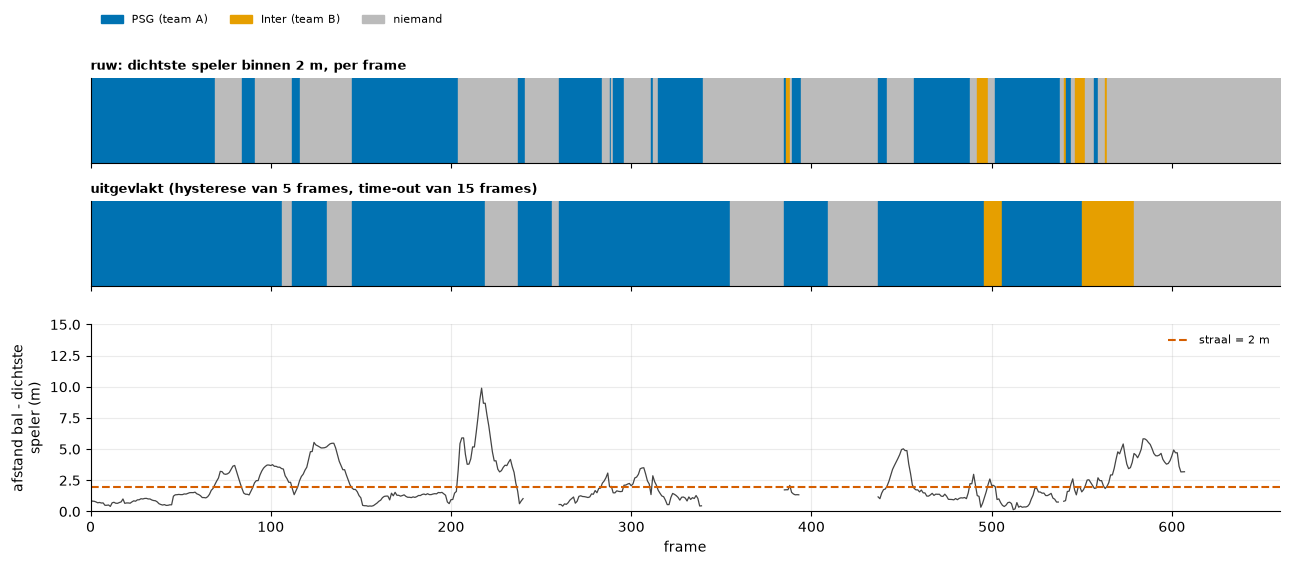

Aandeel van de frames met balbezit: {'PSG (team A)': '91.9 %', 'Inter (team B)': '8.1 %'}
Frames zonder balbezit (team '-'): 181 van 660
Wissels van team: 3
Spelers die het vaakst 'de bal hebben' (track-ID: frames): [(22, 90), (10, 69), (2, 61), (23, 35), (20, 11)]
Afstand bal - dichtste speler: mediaan 1.6 m; 60 % van de frames met bal binnen 2 m


In [29]:
raw_poss, near = {}, {}
for i in base.ids:
    b = base.ball.get(i)
    ball_xy = (b["x_m"], b["y_m"]) if b else None
    raw_poss[i], _ = poss.raw_possession(base.people[i], ball_xy)
    pl = [p for p in base.people[i] if p["team"] in ("A", "B")]
    near[i] = min((np.hypot(p["x_m"] - b["x_m"], p["y_m"] - b["y_m"]) for p in pl), default=np.nan) if b and pl else np.nan
stable = {i: base.possession[i]["team"] for i in base.ids}
fig, axes = plt.subplots(3, 1, figsize=(13, 5.8), sharex=True, gridspec_kw={"height_ratios": [1, 1, 2.2]})
for ax, seq, title in ((axes[0], [raw_poss[i] or "-" for i in base.ids], "ruw: dichtste speler binnen 2 m, per frame"),
                       (axes[1], [stable[i] for i in base.ids], "uitgevlakt (hysterese van 5 frames, time-out van 15 frames)")):
    for t, a, b in runs_of(seq):
        ax.broken_barh([(a, b - a + 1)], (0, 1), color=C[t])
    ax.set_yticks([])
    ax.set_ylim(0, 1)
    ax.set_title(title, loc="left", fontsize=9)
    ax.grid(False)
axes[0].legend([Rectangle((0, 0), 1, 1, color=C[t]) for t in ("A", "B", "-")], [NAME[t] for t in ("A", "B", "-")], ncol=3,
               loc="lower left", bbox_to_anchor=(0, 1.5), fontsize=8)
ax = axes[2]
ax.plot(base.ids, [near[i] for i in base.ids], color="#444444", lw=0.9)
ax.axhline(poss.POSSESSION_RADIUS, color="#D55E00", ls="--", label=f"straal = {poss.POSSESSION_RADIUS:g} m")
ax.set_ylim(0, 15)
ax.set_ylabel("afstand bal - dichtste\nspeler (m)")
ax.set_xlabel("frame")
ax.set_xlim(0, 660)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
share = pipe.possession_share(base)
print("Aandeel van de frames met balbezit:", {NAME[k]: f"{v:.1f} %" for k, v in share.items()})
print("Frames zonder balbezit (team '-'):", sum(stable[i] == "-" for i in base.ids), "van", len(base.ids))
print("Wissels van team:", possession_changes(base))
own = Counter(base.possession[i]["track_id"] for i in base.ids if base.possession[i]["track_id"] is not None)
print("Spelers die het vaakst 'de bal hebben' (track-ID: frames):", own.most_common(5))
dist_ok = np.array([v for v in near.values() if not np.isnan(v)])
print(f"Afstand bal - dichtste speler: mediaan {np.median(dist_ok):.1f} m; {100 * (dist_ok <= 2).mean():.0f} % van de frames met bal binnen 2 m")

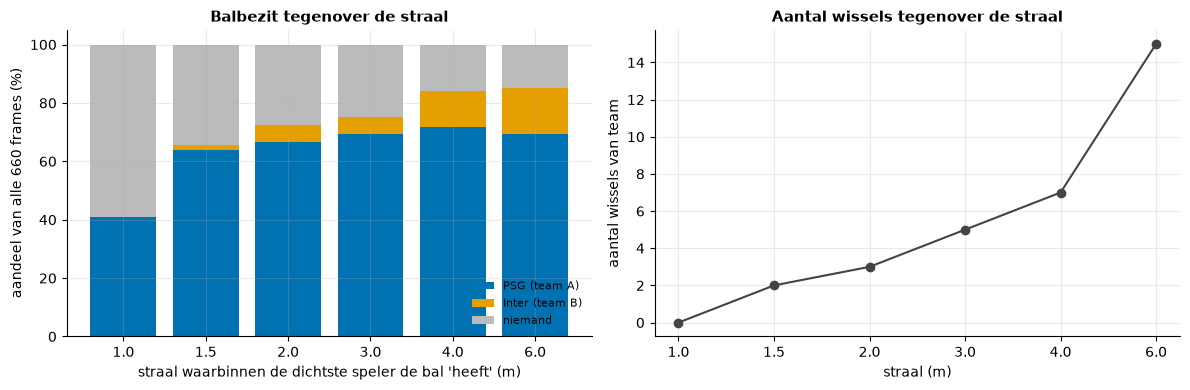

,PSG,Inter,niemand,wissels
straal (m),,,,
1.0,41.1,0.0,58.9,0
1.5,63.9,1.7,34.4,2
2.0,66.7,5.9,27.4,3
3.0,69.4,5.8,24.8,5
4.0,71.7,12.6,15.8,7
6.0,69.2,15.8,15.0,15


In [30]:
def possession_stats(st):
    sl = [st[i] for i in base.ids]
    seq = [t for t in sl if t]
    return {"PSG": 100 * sl.count("A") / len(sl), "Inter": 100 * sl.count("B") / len(sl),
            "niemand": 100 * sum(t is None for t in sl) / len(sl), "wissels": sum(a != b for a, b in zip(seq[:-1], seq[1:]))}


rows = []
for r in [1.0, 1.5, 2.0, 3.0, 4.0, 6.0]:
    rr = {i: poss.raw_possession(base.people[i], (base.ball[i]["x_m"], base.ball[i]["y_m"]) if i in base.ball else None, radius=r)[0] for i in base.ids}
    rows.append({"straal (m)": r, **possession_stats(poss.stable_possession(rr))})
sens_r = pd.DataFrame(rows).set_index("straal (m)")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bot = np.zeros(len(sens_r))
for col, key in (("PSG", "A"), ("Inter", "B"), ("niemand", "-")):
    axes[0].bar([str(r) for r in sens_r.index], sens_r[col], bottom=bot, color=C[key], label=NAME[key])
    bot += sens_r[col].values
axes[0].set_xlabel("straal waarbinnen de dichtste speler de bal 'heeft' (m)")
axes[0].set_ylabel("aandeel van alle 660 frames (%)")
axes[0].set_title("Balbezit tegenover de straal")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].plot([str(r) for r in sens_r.index], sens_r["wissels"], "o-", color="#444444")
axes[1].set_xlabel("straal (m)")
axes[1].set_ylabel("aantal wissels van team")
axes[1].set_title("Aantal wissels tegenover de straal")
plt.tight_layout()
plt.show()
display(sens_r.round(1))

In [31]:
rows = []
for sw in (1, 5, 15, 30):
    for to in (5, 15, 45):
        s = possession_stats(poss.stable_possession(raw_poss, switch=sw, timeout=to))
        rows.append({"switch": sw, "timeout": to, "PSG %": round(s["PSG"], 1), "Inter %": round(s["Inter"], 1), "wissels": s["wissels"]})
display(pd.DataFrame(rows).pivot(index="switch", columns="timeout", values=["PSG %", "Inter %", "wissels"]))

PSG %             Inter %            wissels          
timeout    5     15    45      5    15    45      5    15   45
switch                                                        
1        52.7  66.4  81.5     4.7  6.2  10.8     9.0  9.0  9.0
5        53.0  66.7  81.8     4.4  5.9  10.5     3.0  3.0  3.0
15       57.4  72.6  92.3     0.0  0.0   0.0     0.0  0.0  0.0
30       57.4  72.6  92.3     0.0  0.0   0.0     0.0  0.0  0.0

**Wat zien we.** Over de clip heeft PSG 91,9 % en Inter 8,1 % van de frames met balbezit (479 frames; 181 frames hebben geen balbezit, waarvan 161 zonder bal). Er zijn 3 wissels. PSG heeft de bal van het begin tot ongeveer frame 495; Inter krijgt de bal rond 495-505 en vanaf ±550 tot 580. De spelers met de meeste frames bezit zijn track 22 (90 frames), 10 (69) en 2 (61), allemaal PSG. De mediane afstand tussen de bal en de dichtste speler is 1,6 m; in 60 % van de frames met bal ligt die binnen 2 m. De onderste grafiek toont dat de afstand tijdens een pass of schot sterk stijgt (tot 10 m bij frame 216), dus dat 'niemand' zeker deels echt een losse bal betekent.

**Gevoeligheid voor de straal.** Een grotere straal geeft meer bezit en meer wissels: van 41 % PSG bij 1 m (59 % 'niemand', geen wissels) naar 67 % PSG, 6 % Inter, 27 % niemand en 3 wissels bij 2 m, tot 69 % / 16 % / 15 % en 15 wissels bij 6 m. Bij 1 m heeft in 59 % van de frames niemand de bal, omdat de dichtste speler vaak tussen 1 en 2 m van de bal staat (de mediaan is 1,6 m); bij 6 m wisselt het bezit 15 keer, omdat dan ook spelers die er alleen dichtbij staan de bal 'krijgen'. We kiezen 2 m als compromis; die straal is een keuze, niet gemeten. De tabel met `switch` en `timeout` toont dat de hysterese bepalender is dan de straal: bij `switch` = 15 of hoger verdwijnt Inter helemaal (0 wissels), want al het Inter-bezit bestaat uit stukken korter dan 15 frames. De 8,1 % voor Inter is daarmee een gevoelig getal, gebaseerd op ongeveer 39 frames. Hoe vaak het balbezit klopt volgens de handgelabelde frames staat in notebook 06.

## 7. Gevoeligheid van de post-processing

Twee instellingen bepalen hoeveel frames een bal krijgen: de baldrempel (`ball_conf`) en het grootste gat dat geinterpoleerd wordt (`MAX_BALL_GAP`). We laten de hele clip bij 1280 telkens opnieuw doorrekenen (vijf drempels x vijf gatgroottes = 25 runs, elk ±2 s uit de cache) en tellen drie dingen: het aantal frames met een bal, op hoeveel van de 21 handgelabelde frames met zichtbare bal we een bal geven en op hoeveel van de 7 frames zonder zichtbare bal we toch een bal geven. Let op: met 28 labels zijn verschillen van 1 of 2 frames niet significant; de grafieken tonen de richting, geen precieze optimum.

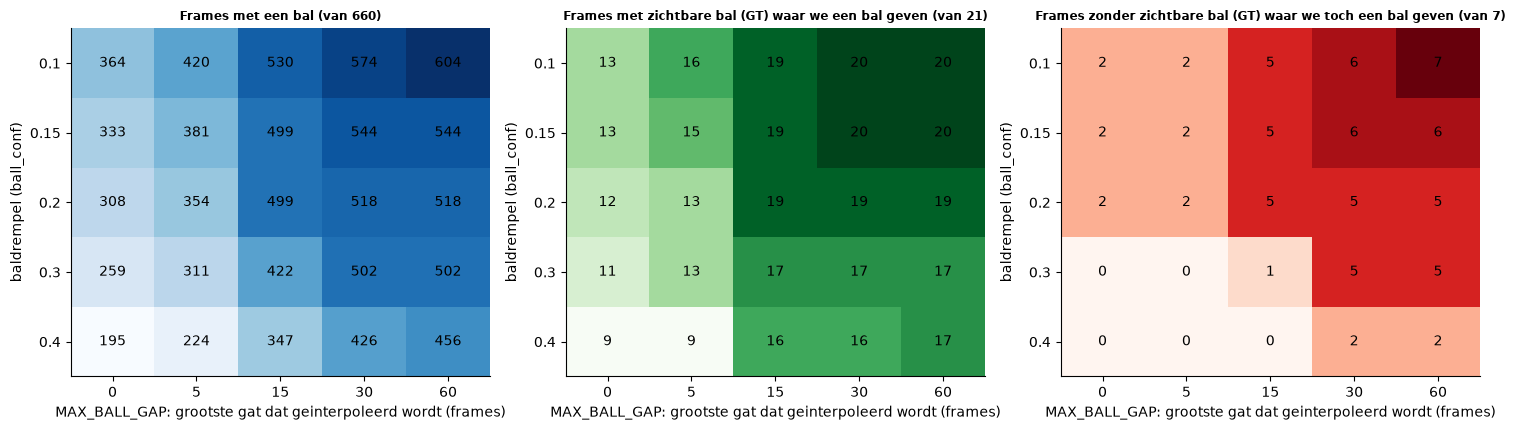

Bij de standaardgrootte van het gat (15 frames), per baldrempel:


,detected,met bal,GT gegeven,valse bal
0.10,364,530,19,5
0.15,333,499,19,5
0.20,308,499,19,5
0.30,259,422,17,1
0.40,195,347,16,0


In [32]:
gaps_ = [0, 5, 15, 30, 60]
confs_ = [0.1, 0.15, 0.2, 0.3, 0.4]
grid = {}
for g in gaps_:
    for c in confs_:
        res = analyse(1280, c, MAX_BALL_GAP=g)
        st = Counter(ball_states(res))
        gt = gt_ball_check(res)
        grid[(g, c)] = {"met bal": st["detected"] + st["interpolated"], "detected": st["detected"], "GT gegeven": gt["given"], "valse bal": gt["false"]}
G = pd.DataFrame(grid).T
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, col, title, cmap in ((axes[0], "met bal", "Frames met een bal (van 660)", "Blues"),
                             (axes[1], "GT gegeven", "Frames met zichtbare bal (GT) waar we een bal geven (van 21)", "Greens"),
                             (axes[2], "valse bal", "Frames zonder zichtbare bal (GT) waar we toch een bal geven (van 7)", "Reds")):
    m = G[col].unstack(level=0).loc[confs_, gaps_]
    ax.imshow(m.values, cmap=cmap, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, int(m.values[i, j]), ha="center", va="center", fontsize=10)
    ax.set_xticks(range(len(gaps_)), gaps_)
    ax.set_yticks(range(len(confs_)), confs_)
    ax.set_xlabel("MAX_BALL_GAP: grootste gat dat geinterpoleerd wordt (frames)")
    ax.set_ylabel("baldrempel (ball_conf)")
    ax.set_title(title, fontsize=8.5)
    ax.grid(False)
plt.tight_layout()
plt.show()
print("Bij de standaardgrootte van het gat (15 frames), per baldrempel:")
display(G.xs(15, level=0)[["detected", "met bal", "GT gegeven", "valse bal"]])

In [33]:
# Effect of the ball threshold and gap on the possession result.
rows = []
for g, c in ((0, 0.2), (15, 0.2), (30, 0.2), (15, 0.1), (15, 0.4)):
    res = analyse(1280, c, MAX_BALL_GAP=g)
    share = pipe.possession_share(res)
    rows.append({"MAX_BALL_GAP": g, "baldrempel": c, "frames met bal": len(res.ball), "bezit PSG %": round(share.get("A", 0), 1),
                 "bezit Inter %": round(share.get("B", 0), 1), "wissels": possession_changes(res)})
display(pd.DataFrame(rows))

,MAX_BALL_GAP,baldrempel,frames met bal,bezit PSG %,bezit Inter %,wissels
0,0,0.2,308,100.0,0.0,0
1,15,0.2,499,91.9,8.1,3
2,30,0.2,518,91.9,8.1,3
3,15,0.1,530,88.3,11.7,3
4,15,0.4,347,87.7,12.3,5


**Wat zien we.**

- *Gat.* Interpolatie is de grootste hefboom: bij baldrempel 0,2 gaat het aantal frames met bal van 308 (geen interpolatie) naar 354 (gat 5), 499 (gat 15, de standaard), 518 (gat 30) en blijft 518 bij 60. Boven 30 frames is er bij deze drempel geen gat meer om te vullen (binnen één segment). Het aantal gevonden handgelabelde ballen stijgt van 12 naar 19, maar de valse ballen van 2 naar 5 en bij ruime gaten bij lage drempel naar 6 tot 7: wie gaten vult, vult ook gaten waarin de bal echt niet zichtbaar is (de bal achter een speler, in het doel).
- *Drempel.* Bij gat 15 geven drempels 0,1 tot 0,2 hetzelfde aantal gevonden ballen (19) en hetzelfde aantal valse ballen (5). Vanaf 0,3 verliezen we twee gevonden ballen (17) en zakt het aantal valse ballen naar 1; bij 0,4 vinden we 16 en geven we nooit een valse bal. Hoger is dus 'voorzichtiger': minder frames met bal (347 bij 0,4 tegenover 499 bij 0,2), meer 'geen bal'. De gekozen 0,2 ligt precies op de rand waar de gevonden ballen nog volledig zijn.
- Op balbezit: zonder interpolatie wordt het bezit 100 % PSG (Inter komt alleen in geinterpoleerde frames in het spel), met het standaardgat is het 91,9 % / 8,1 %, en bij drempel 0,4 87,7 % / 12,3 % met 5 wissels. Ook hier verandert een instelling van de bal de uitkomst van het balbezit.

## 8. Conclusies

- **Spelers volgen.** ByteTrack met onze instellingen (buffer 30, koppeldrempel 0,8, tweede ronde met zwakke boxen) geeft 41 tracks voor 22 spelers plus de scheidsrechtersgroep: 19 tracks lopen vrijwel de hele clip door, 14 duren minder dan 2 s. De koppeldrempel is gevoeliger dan de buffer (0,6: 143 tracks; 0,9: 37-39). Of identiteiten wisselen kunnen we niet meten; we vinden minstens 5 vermoedelijke onderbrekingen.
- **Teams.** Eén stem per track corrigeert 0,96 % van de frames, vooral in één scheidsrechterstrack. De K-means-terugval scheidt de spelers voor 97,6 % goed op shirtkleur (op onze eigen detecties), maar de koppeling team 1 = PSG klopt niet, scheidsrechter en keeper worden maar half herkend, en hij is niet met een echt COCO-model getest.
- **De bal.** Met een mediaan van 14 px en een mediane confidence van 0,17 is de bal het moeilijkste object. Een Kalman-filter in meters met een kandidatenfilter en de gate-fix geeft in 499 van de 660 frames een bal (308 gedetecteerd, 191 geinterpoleerd). In 161 frames is er geen bal, meestal omdat hij echt niet te zien is.
- **De experimenten.** De winst zat in het repareren van de tracker, niet in voorspellen; opgeschaalde crops, extrapolatie en visuele trackers werken niet of voegen valse ballen toe. De varianten uit de cache rekenen we exact na (302/119/239, 332/136/192, 332/136/1/191); het balbezit uit de eerdere rapporten rekenen we niet exact na.
- **Balbezit.** PSG 91,9 %, Inter 8,1 % van 479 frames met bezit, 3 wissels. De uitkomst hangt af van de straal (2 m is een keuze), de hysterese en de baldrempel; de 8,1 % voor Inter berust op ongeveer 39 frames.
- **Gevoeligheid.** Het gat voor interpolatie (0, 5, 15, 30, 60) en de drempel (0,1 tot 0,4) verschuiven het aantal frames met bal van 195 tot 604 en het aantal valse ballen op de handgelabelde frames van 0 tot 7.

## 9. Beperkingen

- *Geen identiteitsmeting.* ID-switches zijn niet gemeten (geen handgelabelde identiteiten over de tijd); onze lijst van 5 vermoedelijke onderbrekingen is een ondergrens van een heuristiek, geen meting. Afstanden en snelheden per track in notebook 05 zijn daardoor ondergrenzen.
- *De bal in de lucht.* De homografie zet het beeldpunt om alsof de bal op het gras ligt; bij een bal in de lucht is de positie op het veld fout, en dat beïnvloedt zowel de baltrack als het balbezit.
- *Dode-balfases.* In de periodes dat de bal in het doel of bij de keeper ligt, is hij niet te zien; die stukken blijven leeg, ook met herdetectie.
- *De experimenten* zijn gedaan op één clip van 660 frames met 28 handgelabelde ballen (21 zichtbaar, 7 niet); verschillen van 1 tot 2 frames zijn niet significant. De crop- en tracker-simulaties zijn optimistisch omdat het model of de tracker het echte frame ziet.
- *Herdetectie niet gedraaid op de huidige standaard.* De crop-cache hoort bij imgsz 960 en drempel 0,1; voor 1280 en 0,2 ontbreken 156 crops en we hebben YOLO hier niet gestart. Het effect van herdetectie op de nieuwe standaard is dus niet gemeten.
- *Balbezit* is een afstandsregel zonder kennis van het spel; de uitkomst is gevoelig voor de straal, de hysterese en de balpositie. De afwijking met de eerder gerapporteerde balbezitcijfers is niet opgehelderd.
- *K-means-terugval* niet getest met een COCO-model; team 1 / team 2 is niet gekoppeld aan PSG / Inter.
- *Meer dan één scheidsrechter.* De groep 'scheidsrechter' bevat gemiddeld 2,8 personen per frame (waarschijnlijk de scheidsrechter en assistent-scheidsrechters aan de rand van het veld); dat hebben we niet per persoon gecontroleerd.